# 1. Análisis exploratorio de datos (EDA)

**Objetivo del proyecto:** predecir si un préstamo de Lending Club termina en *default*
(`Charged Off` = 1) o se paga completamente (`Fully Paid` = 0), comparando seis modelos
implementados en scikit-learn y en PySpark.

Este notebook cubre las secciones 2.1 a 2.5 del enunciado: carga completa del dataset
(sin muestreo), análisis unidimensional, bidimensional, multicolinealidad, valores
faltantes y un resumen ejecutivo con las decisiones que guían el preprocesamiento.

> **Nota sobre la definición del target.** La fórmula del enunciado
> `df["default"] = df["loan_status"].apply(lambda x: 1 if x == "Charged Off" else 0)`
> aplicada al archivo completo etiquetaría como "pagados" (0) a los préstamos `Current`,
> `Late`, `In Grace Period`, etc., que **todavía no tienen un desenlace observado**. Eso sería
> un error de etiquetado. Por ello primero se conservan solo los préstamos con estado final
> (`Fully Paid` / `Charged Off`) y después se aplica la fórmula literal. Esto no es un muestreo:
> se usan **todas** las filas con desenlace conocido (1.345.310, coherente con los "más de
> 1,3 millones de registros" del enunciado).

In [1]:
import sys  # Permite modificar la ruta de búsqueda de módulos
sys.path.insert(0, "..")  # Agrega la raíz del proyecto para poder importar src/
import time  # Medición de tiempos
import warnings  # Control de advertencias
import numpy as np  # Cálculo numérico
import pandas as pd  # Manipulación de datos tabulares
import matplotlib.pyplot as plt  # Gráficos
import seaborn as sns  # Gráficos estadísticos
import missingno as msno  # Visualización de valores faltantes
from scipy import stats  # Pruebas estadísticas
from src import config as cfg  # Configuración central del proyecto
from src import preparacion as prep  # Construcción de variables con pandas
from src.utilidades import guardar_figura, info_hardware  # Utilidades auxiliares

warnings.filterwarnings("ignore", category=FutureWarning)  # Oculta avisos de versiones futuras de librerías
pd.set_option("display.max_columns", 60)  # Muestra hasta 60 columnas en las tablas
pd.set_option("display.width", 200)  # Ancho máximo de impresión de tablas
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")  # Formato de los números flotantes
sns.set_theme(style="whitegrid", palette="deep")  # Estilo general de los gráficos
print(info_hardware())  # Muestra el hardware utilizado

{'sistema': 'Windows 10', 'procesador': 'AMD64 Family 25 Model 117 Stepping 2, AuthenticAMD', 'nucleos_fisicos': 6, 'nucleos_logicos': 12, 'ram_total_gb': 13.8, 'ram_disponible_gb': 6.0, 'python': '3.9.25'}


## 2.2 Carga inicial y visión general

Se carga el CSV comprimido **completo** con pandas y, a modo de comparación, con Spark.

In [2]:
inicio = time.time()  # Marca de tiempo antes de la carga
df_raw = pd.read_csv(cfg.RUTA_CSV, low_memory=False)  # Lee el archivo completo (pandas descomprime el .gz)
t_pandas = time.time() - inicio  # Tiempo total de carga con pandas
print(f"Tiempo de carga con pandas: {t_pandas:.1f} s")  # Reporta el tiempo
print(f"Dimensión: {df_raw.shape[0]:,} filas × {df_raw.shape[1]} columnas")  # Reporta filas y columnas
print(f"Memoria en uso: {df_raw.memory_usage(deep=True).sum() / 1024**3:.2f} GB")  # Memoria ocupada por el DataFrame

Tiempo de carga con pandas: 48.9 s
Dimensión: 2,260,701 filas × 151 columnas


Memoria en uso: 6.26 GB


In [3]:
from src import preparacion_spark as prep_sp  # Funciones de Spark del proyecto
spark = prep_sp.crear_sesion()  # Crea la SparkSession con la configuración del enunciado
inicio = time.time()  # Marca de tiempo antes de la carga
n_spark = prep_sp.leer_csv(spark).count()  # Lee el CSV completo con Spark y fuerza la lectura contando filas
t_spark = time.time() - inicio  # Tiempo total de carga con Spark
print(f"Tiempo de carga con Spark: {t_spark:.1f} s  ({n_spark:,} filas)")  # Reporta tiempo y filas
spark.stop()  # Detiene la sesión para liberar memoria

Tiempo de carga con Spark: 15.9 s  (2,260,701 filas)


**Comentario.** El archivo tiene **2.260.701 filas × 151 columnas** y ocupa ≈ 6,3 GB en
memoria con pandas, que tardó ≈ 72 s en leerlo. Spark contó las mismas filas en ≈ 17 s: un
`.gz` no es divisible (se descomprime en un solo hilo), pero Spark no construye objetos de
Python ni infiere tipos, y para un `count()` apenas necesita tokenizar cada registro. La
comparación favorece a Spark sobre todo porque su lectura es perezosa: pandas materializa
todas las columnas tipadas. `head()`/`tail()` confirman una lectura correcta; las dos últimas
filas son **totales del archivo** (sin `loan_status`) y quedan fuera al filtrar estados.

In [4]:
df_raw.head()  # Primeras 5 filas para verificar la lectura

,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,emp_title,emp_length,home_ownership,annual_inc,verification_status,issue_d,loan_status,pymnt_plan,url,desc,purpose,title,zip_code,addr_state,dti,delinq_2yrs,earliest_cr_line,fico_range_low,fico_range_high,inq_last_6mths,...,sec_app_open_acc,sec_app_revol_util,sec_app_open_act_il,sec_app_num_rev_accts,sec_app_chargeoff_within_12_mths,sec_app_collections_12_mths_ex_med,sec_app_mths_since_last_major_derog,hardship_flag,hardship_type,hardship_reason,hardship_status,deferral_term,hardship_amount,hardship_start_date,hardship_end_date,payment_plan_start_date,hardship_length,hardship_dpd,hardship_loan_status,orig_projected_additional_accrued_interest,hardship_payoff_balance_amount,hardship_last_payment_amount,disbursement_method,debt_settlement_flag,debt_settlement_flag_date,settlement_status,settlement_date,settlement_amount,settlement_percentage,settlement_term
0,68407277,NaN,"3,600.0000","3,600.0000","3,600.0000",36 months,13.9900,123.0300,C,C4,leadman,10+ years,MORTGAGE,"55,000.0000",Not Verified,Dec-2015,Fully Paid,n,https://lendingclub.com/browse/loanDetail.acti...,NaN,debt_consolidation,Debt consolidation,190xx,PA,5.9100,0.0000,Aug-2003,675.0000,679.0000,1.0000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,N,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
1,68355089,NaN,"24,700.0000","24,700.0000","24,700.0000",36 months,11.9900,820.2800,C,C1,Engineer,10+ years,MORTGAGE,"65,000.0000",Not Verified,Dec-2015,Fully Paid,n,https://lendingclub.com/browse/loanDetail.acti...,NaN,small_business,Business,577xx,SD,16.0600,1.0000,Dec-1999,715.0000,719.0000,4.0000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,N,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
2,68341763,NaN,"20,000.0000","20,000.0000","20,000.0000",60 months,10.7800,432.6600,B,B4,truck driver,10+ years,MORTGAGE,"63,000.0000",Not Verified,Dec-2015,Fully Paid,n,https://lendingclub.com/browse/loanDetail.acti...,NaN,home_improvement,NaN,605xx,IL,10.7800,0.0000,Aug-2000,695.0000,699.0000,0.0000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,N,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
3,66310712,NaN,"35,000.0000","35,000.0000","35,000.0000",60 months,14.8500,829.9000,C,C5,Information Systems Officer,10+ years,MORTGAGE,"110,000.0000",Source Verified,Dec-2015,Current,n,https://lendingclub.com/browse/loanDetail.acti...,NaN,debt_consolidation,Debt consolidation,076xx,NJ,17.0600,0.0000,Sep-2008,785.0000,789.0000,0.0000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,N,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
4,68476807,NaN,"10,400.0000","10,400.0000","10,400.0000",60 months,22.4500,289.9100,F,F1,Contract Specialist,3 years,MORTGAGE,"104,433.0000",Source Verified,Dec-2015,Fully Paid,n,https://lendingclub.com/browse/loanDetail.acti...,NaN,major_purchase,Major purchase,174xx,PA,25.3700,1.0000,Jun-1998,695.0000,699.0000,3.0000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,N,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
df_raw.tail()  # Últimas 5 filas: las dos últimas son filas de totales, no préstamos

,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,emp_title,emp_length,home_ownership,annual_inc,verification_status,issue_d,loan_status,pymnt_plan,url,desc,purpose,title,zip_code,addr_state,dti,delinq_2yrs,earliest_cr_line,fico_range_low,fico_range_high,inq_last_6mths,...,sec_app_open_acc,sec_app_revol_util,sec_app_open_act_il,sec_app_num_rev_accts,sec_app_chargeoff_within_12_mths,sec_app_collections_12_mths_ex_med,sec_app_mths_since_last_major_derog,hardship_flag,hardship_type,hardship_reason,hardship_status,deferral_term,hardship_amount,hardship_start_date,hardship_end_date,payment_plan_start_date,hardship_length,hardship_dpd,hardship_loan_status,orig_projected_additional_accrued_interest,hardship_payoff_balance_amount,hardship_last_payment_amount,disbursement_method,debt_settlement_flag,debt_settlement_flag_date,settlement_status,settlement_date,settlement_amount,settlement_percentage,settlement_term
2260696,88985880,NaN,"40,000.0000","40,000.0000","40,000.0000",60 months,10.4900,859.5600,B,B3,Vice President,9 years,MORTGAGE,"227,000.0000",Verified,Oct-2016,Current,n,https://lendingclub.com/browse/loanDetail.acti...,NaN,debt_consolidation,NaN,907xx,CA,12.7500,7.0000,Feb-1995,705.0000,709.0000,1.0000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,N,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
2260697,88224441,NaN,"24,000.0000","24,000.0000","24,000.0000",60 months,14.4900,564.5600,C,C4,Program Manager,6 years,RENT,"110,000.0000",Not Verified,Oct-2016,Charged Off,n,https://lendingclub.com/browse/loanDetail.acti...,NaN,debt_consolidation,Debt consolidation,334xx,FL,18.3000,0.0000,Jul-1999,660.0000,664.0000,0.0000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,N,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Cash,Y,Mar-2019,ACTIVE,Mar-2019,"10,000.0000",44.8200,1.0000
2260698,88215728,NaN,"14,000.0000","14,000.0000","14,000.0000",60 months,14.4900,329.3300,C,C4,Customer Service Technician,10+ years,MORTGAGE,"95,000.0000",Verified,Oct-2016,Current,n,https://lendingclub.com/browse/loanDetail.acti...,NaN,debt_consolidation,NaN,770xx,TX,23.3600,0.0000,Jun-1996,660.0000,664.0000,1.0000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,N,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
2260699,Total amount funded in policy code 1: 1465324575,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2260700,Total amount funded in policy code 2: 521953170,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
df_raw.info(verbose=True, show_counts=True)  # Tipos de datos y conteo de no nulos de cada columna

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2260701 entries, 0 to 2260700
Data columns (total 151 columns):
 #    Column                                      Non-Null Count    Dtype  
---   ------                                      --------------    -----  
 0    id                                          2260701 non-null  object 
 1    member_id                                   0 non-null        float64
 2    loan_amnt                                   2260668 non-null  float64
 3    funded_amnt                                 2260668 non-null  float64
 4    funded_amnt_inv                             2260668 non-null  float64
 5    term                                        2260668 non-null  object 
 6    int_rate                                    2260668 non-null  float64
 7    installment                                 2260668 non-null  float64
 8    grade                                       2260668 non-null  object 
 9    sub_grade                                   

In [7]:
df_raw.describe().T  # Estadísticas descriptivas de todas las variables numéricas

,count,mean,std,min,25%,50%,75%,max
member_id,0.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loan_amnt,"2,260,668.0000","15,046.9312","9,190.2455",500.0000,"8,000.0000","12,900.0000","20,000.0000","40,000.0000"
funded_amnt,"2,260,668.0000","15,041.6641","9,188.4130",500.0000,"8,000.0000","12,875.0000","20,000.0000","40,000.0000"
funded_amnt_inv,"2,260,668.0000","15,023.4377","9,192.3317",0.0000,"8,000.0000","12,800.0000","20,000.0000","40,000.0000"
int_rate,"2,260,668.0000",13.0928,4.8321,5.3100,9.4900,12.6200,15.9900,30.9900
...,...,...,...,...,...,...,...,...
hardship_payoff_balance_amount,"10,917.0000","11,636.8839","7,625.9883",55.7300,"5,627.0000","10,028.3900","16,151.8900","40,306.4100"
hardship_last_payment_amount,"10,917.0000",193.9943,198.6295,0.0100,44.4400,133.1600,284.1900,"1,407.8600"
settlement_amount,"34,246.0000","5,010.6643","3,693.1226",44.2100,"2,208.0000","4,146.1100","6,850.1725","33,601.0000"
settlement_percentage,"34,246.0000",47.7804,7.3118,0.2000,45.0000,45.0000,50.0000,521.3500


In [8]:
estados = df_raw[cfg.COL_ESTADO].value_counts(dropna=False).to_frame("n")  # Frecuencia de cada estado del préstamo
estados["%"] = 100 * estados["n"] / estados["n"].sum()  # Porcentaje de cada estado
estados  # Muestra la tabla

,n,%
loan_status,,
Fully Paid,1076751,47.6291
Current,878317,38.8515
Charged Off,268559,11.8795
Late (31-120 days),21467,0.9496
In Grace Period,8436,0.3732
Late (16-30 days),4349,0.1924
Does not meet the credit policy. Status:Fully Paid,1988,0.0879
Does not meet the credit policy. Status:Charged Off,761,0.0337
Default,40,0.0018


Solo `Fully Paid` y `Charged Off` representan desenlaces definitivos. `Current` y los
estados de mora son préstamos vivos; las variantes "Does not meet the credit policy" son
préstamos bajo una política distinta y `Default` (40 casos) aún no ha sido castigado.

### Pre-cálculo de faltantes sobre las 151 columnas

Antes de reducir columnas, se calcula la tasa de nulos de **todas** las variables en los
préstamos con desenlace final y su relación con el target. Los resultados se presentan en
la sección de valores faltantes.

In [9]:
finales = df_raw[cfg.COL_ESTADO].isin(cfg.ESTADOS_FINALES).to_numpy()  # Máscara de préstamos con estado final
nulos_fin = df_raw.isna().to_numpy()[finales]  # Matriz booleana de nulos (filas finales × 151 columnas), sin copiar los datos
y_fin = (df_raw.loc[finales, cfg.COL_ESTADO] == "Charged Off").astype(int).to_numpy()  # Target en ese subconjunto
nulos_todas = pd.DataFrame({"n_nulos": nulos_fin.sum(axis=0)}, index=df_raw.columns)  # Número de nulos por columna
nulos_todas["pct_nulos"] = 100 * nulos_todas["n_nulos"] / finales.sum()  # Porcentaje de nulos por columna
nulos_todas = nulos_todas.sort_values("pct_nulos", ascending=False)  # Ordena de mayor a menor

filas_mcar = []  # Lista con la prueba de independencia nulo-vs-default de cada columna
for col in nulos_todas.index[(nulos_todas["pct_nulos"] > 0) & (nulos_todas["pct_nulos"] < 100)]:  # Columnas con nulos parciales
    es_nulo = nulos_fin[:, df_raw.columns.get_loc(col)]  # Indicador de nulo de la columna
    tabla = pd.crosstab(es_nulo, y_fin)  # Tabla 2×2: nulo/no nulo × default
    chi2, p, _, _ = stats.chi2_contingency(tabla)  # Prueba chi-cuadrado de independencia
    filas_mcar.append({  # Guarda el resultado
        "columna": col,  # Nombre de la columna
        "pct_nulos": nulos_todas.loc[col, "pct_nulos"],  # Porcentaje de nulos
        "tasa_default_si_nulo": y_fin[es_nulo].mean(),  # Tasa de default cuando falta el dato
        "tasa_default_si_presente": y_fin[~es_nulo].mean(),  # Tasa de default cuando el dato está
        "chi2": chi2, "p_valor": p,  # Estadístico y valor p
    })
mcar_todas = pd.DataFrame(filas_mcar).set_index("columna")  # Tabla final de la prueba

anio_fin = pd.to_datetime(df_raw.loc[finales, "issue_d"], format="%b-%Y").dt.year.to_numpy()  # Año de emisión de cada préstamo
cols_con_nulos = nulos_todas.index[(nulos_todas["pct_nulos"] > 0)].tolist()  # Columnas con algún nulo
nulos_por_anio = (pd.DataFrame(nulos_fin, columns=df_raw.columns)[cols_con_nulos]  # Nulos de las columnas con faltantes
                  .groupby(anio_fin).mean())  # Proporción de nulos por año de emisión
nulos_por_fila = nulos_fin.sum(axis=1)  # Número de nulos en cada fila

df = prep.construir_variables(df_raw)  # Filtra estados finales y crea variables derivadas + default
del df_raw, nulos_fin  # Libera el DataFrame de 151 columnas y la matriz de nulos
import gc; gc.collect()  # Fuerza la liberación de memoria
print(df.shape)  # Dimensión del dataset de trabajo
df.head()  # Primeras filas del dataset de trabajo

(1345310, 31)


,id,issue_d,loan_amnt,term_meses,int_rate,installment,annual_inc,dti,fico_range_low,fico_range_high,emp_length_anios,delinq_2yrs,inq_last_6mths,open_acc,pub_rec,revol_bal,revol_util,total_acc,mort_acc,pub_rec_bankruptcies,mths_since_last_delinq,antiguedad_credito_meses,grade,sub_grade,home_ownership,verification_status,purpose,addr_state,initial_list_status,application_type,default
0,68407277,2015-12-01,"3,600.0000",36.0000,13.9900,123.0300,"55,000.0000",5.9100,675.0000,679.0000,10.0000,0.0000,1.0000,7.0000,0.0000,"2,765.0000",29.7000,13.0000,1.0000,0.0000,30.0000,148.0000,C,C4,MORTGAGE,Not Verified,debt_consolidation,PA,w,Individual,0
1,68355089,2015-12-01,"24,700.0000",36.0000,11.9900,820.2800,"65,000.0000",16.0600,715.0000,719.0000,10.0000,1.0000,4.0000,22.0000,0.0000,"21,470.0000",19.2000,38.0000,4.0000,0.0000,6.0000,192.0000,C,C1,MORTGAGE,Not Verified,small_business,SD,w,Individual,0
2,68341763,2015-12-01,"20,000.0000",60.0000,10.7800,432.6600,"63,000.0000",10.7800,695.0000,699.0000,10.0000,0.0000,0.0000,6.0000,0.0000,"7,869.0000",56.2000,18.0000,5.0000,0.0000,NaN,184.0000,B,B4,MORTGAGE,Not Verified,home_improvement,IL,w,Joint App,0
3,68476807,2015-12-01,"10,400.0000",60.0000,22.4500,289.9100,"104,433.0000",25.3700,695.0000,699.0000,3.0000,1.0000,3.0000,12.0000,0.0000,"21,929.0000",64.5000,35.0000,6.0000,0.0000,12.0000,210.0000,F,F1,MORTGAGE,Source Verified,major_purchase,PA,w,Individual,0
4,68426831,2015-12-01,"11,950.0000",36.0000,13.4400,405.1800,"34,000.0000",10.2000,690.0000,694.0000,4.0000,0.0000,0.0000,5.0000,0.0000,"8,822.0000",68.4000,6.0000,0.0000,0.0000,NaN,338.0000,C,C3,RENT,Source Verified,debt_consolidation,GA,w,Individual,0


## 2.3 Análisis unidimensional

### Variables numéricas

Para cada variable se reportan media, mediana, desviación estándar, mínimo, máximo,
percentiles, IQR, outliers según la regla de Tukey (fuera de [Q1 − 1.5·IQR, Q3 + 1.5·IQR]),
asimetría, curtosis y la prueba de normalidad de D'Agostino-Pearson (se prefiere a
Shapiro-Wilk porque esta última no es válida con más de 5.000 observaciones y aquí se usa
la muestra completa).

In [10]:
filas = []  # Lista de resúmenes por variable
for col in cfg.NUMERICAS_EDA:  # Recorre cada variable numérica
    x = df[col].dropna()  # Valores no nulos
    q1, q2, q3 = x.quantile([0.25, 0.5, 0.75])  # Cuartiles
    iqr = q3 - q1  # Rango intercuartil
    li, ls = q1 - 1.5 * iqr, q3 + 1.5 * iqr  # Límites de Tukey
    n_out = int(((x < li) | (x > ls)).sum())  # Número de outliers
    filas.append({  # Guarda el resumen de la variable
        "media": x.mean(), "mediana": q2, "desv_est": x.std(),  # Tendencia central y dispersión
        "min": x.min(), "p25": q1, "p50": q2, "p75": q3, "max": x.max(),  # Rango y percentiles
        "IQR": iqr, "lim_inf": li, "lim_sup": ls,  # IQR y límites de outliers
        "n_outliers": n_out, "pct_outliers": 100 * n_out / len(x),  # Cantidad y % de outliers
        "asimetria": stats.skew(x), "curtosis": stats.kurtosis(x),  # Forma de la distribución
        "p_normalidad": stats.normaltest(x).pvalue,  # Prueba de D'Agostino-Pearson
        "pct_nulos": 100 * df[col].isna().mean(),  # Porcentaje de nulos
    })
resumen_num = pd.DataFrame(filas, index=cfg.NUMERICAS_EDA)  # Tabla final
resumen_num  # Muestra la tabla

,media,mediana,desv_est,min,p25,p50,p75,max,IQR,lim_inf,lim_sup,n_outliers,pct_outliers,asimetria,curtosis,p_normalidad,pct_nulos
loan_amnt,"14,419.9720","12,000.0000","8,717.0508",500.0000,"8,000.0000","12,000.0000","20,000.0000","40,000.0000","12,000.0000","-10,000.0000","38,000.0000",7157,0.5320,0.7825,-0.0838,0.0000,0.0000
term_meses,41.7902,36.0000,10.2683,36.0000,36.0000,36.0000,36.0000,60.0000,0.0000,36.0000,36.0000,324567,24.1258,1.2095,-0.5371,0.0000,0.0000
int_rate,13.2396,12.7400,4.7687,5.3100,9.7500,12.7400,15.9900,30.9900,6.2400,0.3900,25.3500,24977,1.8566,0.7135,0.5059,0.0000,0.0000
installment,438.0755,375.4300,261.5126,4.9300,248.4800,375.4300,580.7300,"1,719.8300",332.2500,-249.8950,"1,079.1050",42042,3.1251,1.0065,0.7487,0.0000,0.0000
annual_inc,"76,247.6364","65,000.0000","69,925.0984",0.0000,"45,780.0000","65,000.0000","90,000.0000","10,999,200.0000","44,220.0000","-20,550.0000","156,330.0000",65870,4.8963,46.3179,"4,812.4144",0.0000,0.0000
dti,18.2827,17.6100,11.1604,-1.0000,11.7900,17.6100,24.0600,999.0000,12.2700,-6.6150,42.4650,5473,0.4069,27.1106,"2,112.6827",0.0000,0.0278
fico_range_low,696.1850,690.0000,31.8525,625.0000,670.0000,690.0000,710.0000,845.0000,40.0000,610.0000,770.0000,46497,3.4562,1.2855,1.6618,0.0000,0.0000
fico_range_high,700.1852,694.0000,31.8532,629.0000,674.0000,694.0000,714.0000,850.0000,40.0000,614.0000,774.0000,46497,3.4562,1.2857,1.6631,0.0000,0.0000
emp_length_anios,5.9659,6.0000,3.6912,0.0000,2.0000,6.0000,10.0000,10.0000,8.0000,-10.0000,22.0000,0,0.0000,-0.2172,-1.4991,0.0000,5.8359
delinq_2yrs,0.3178,0.0000,0.8780,0.0000,0.0000,0.0000,0.0000,39.0000,0.0000,0.0000,0.0000,259251,19.2707,5.6036,58.6917,0.0000,0.0000


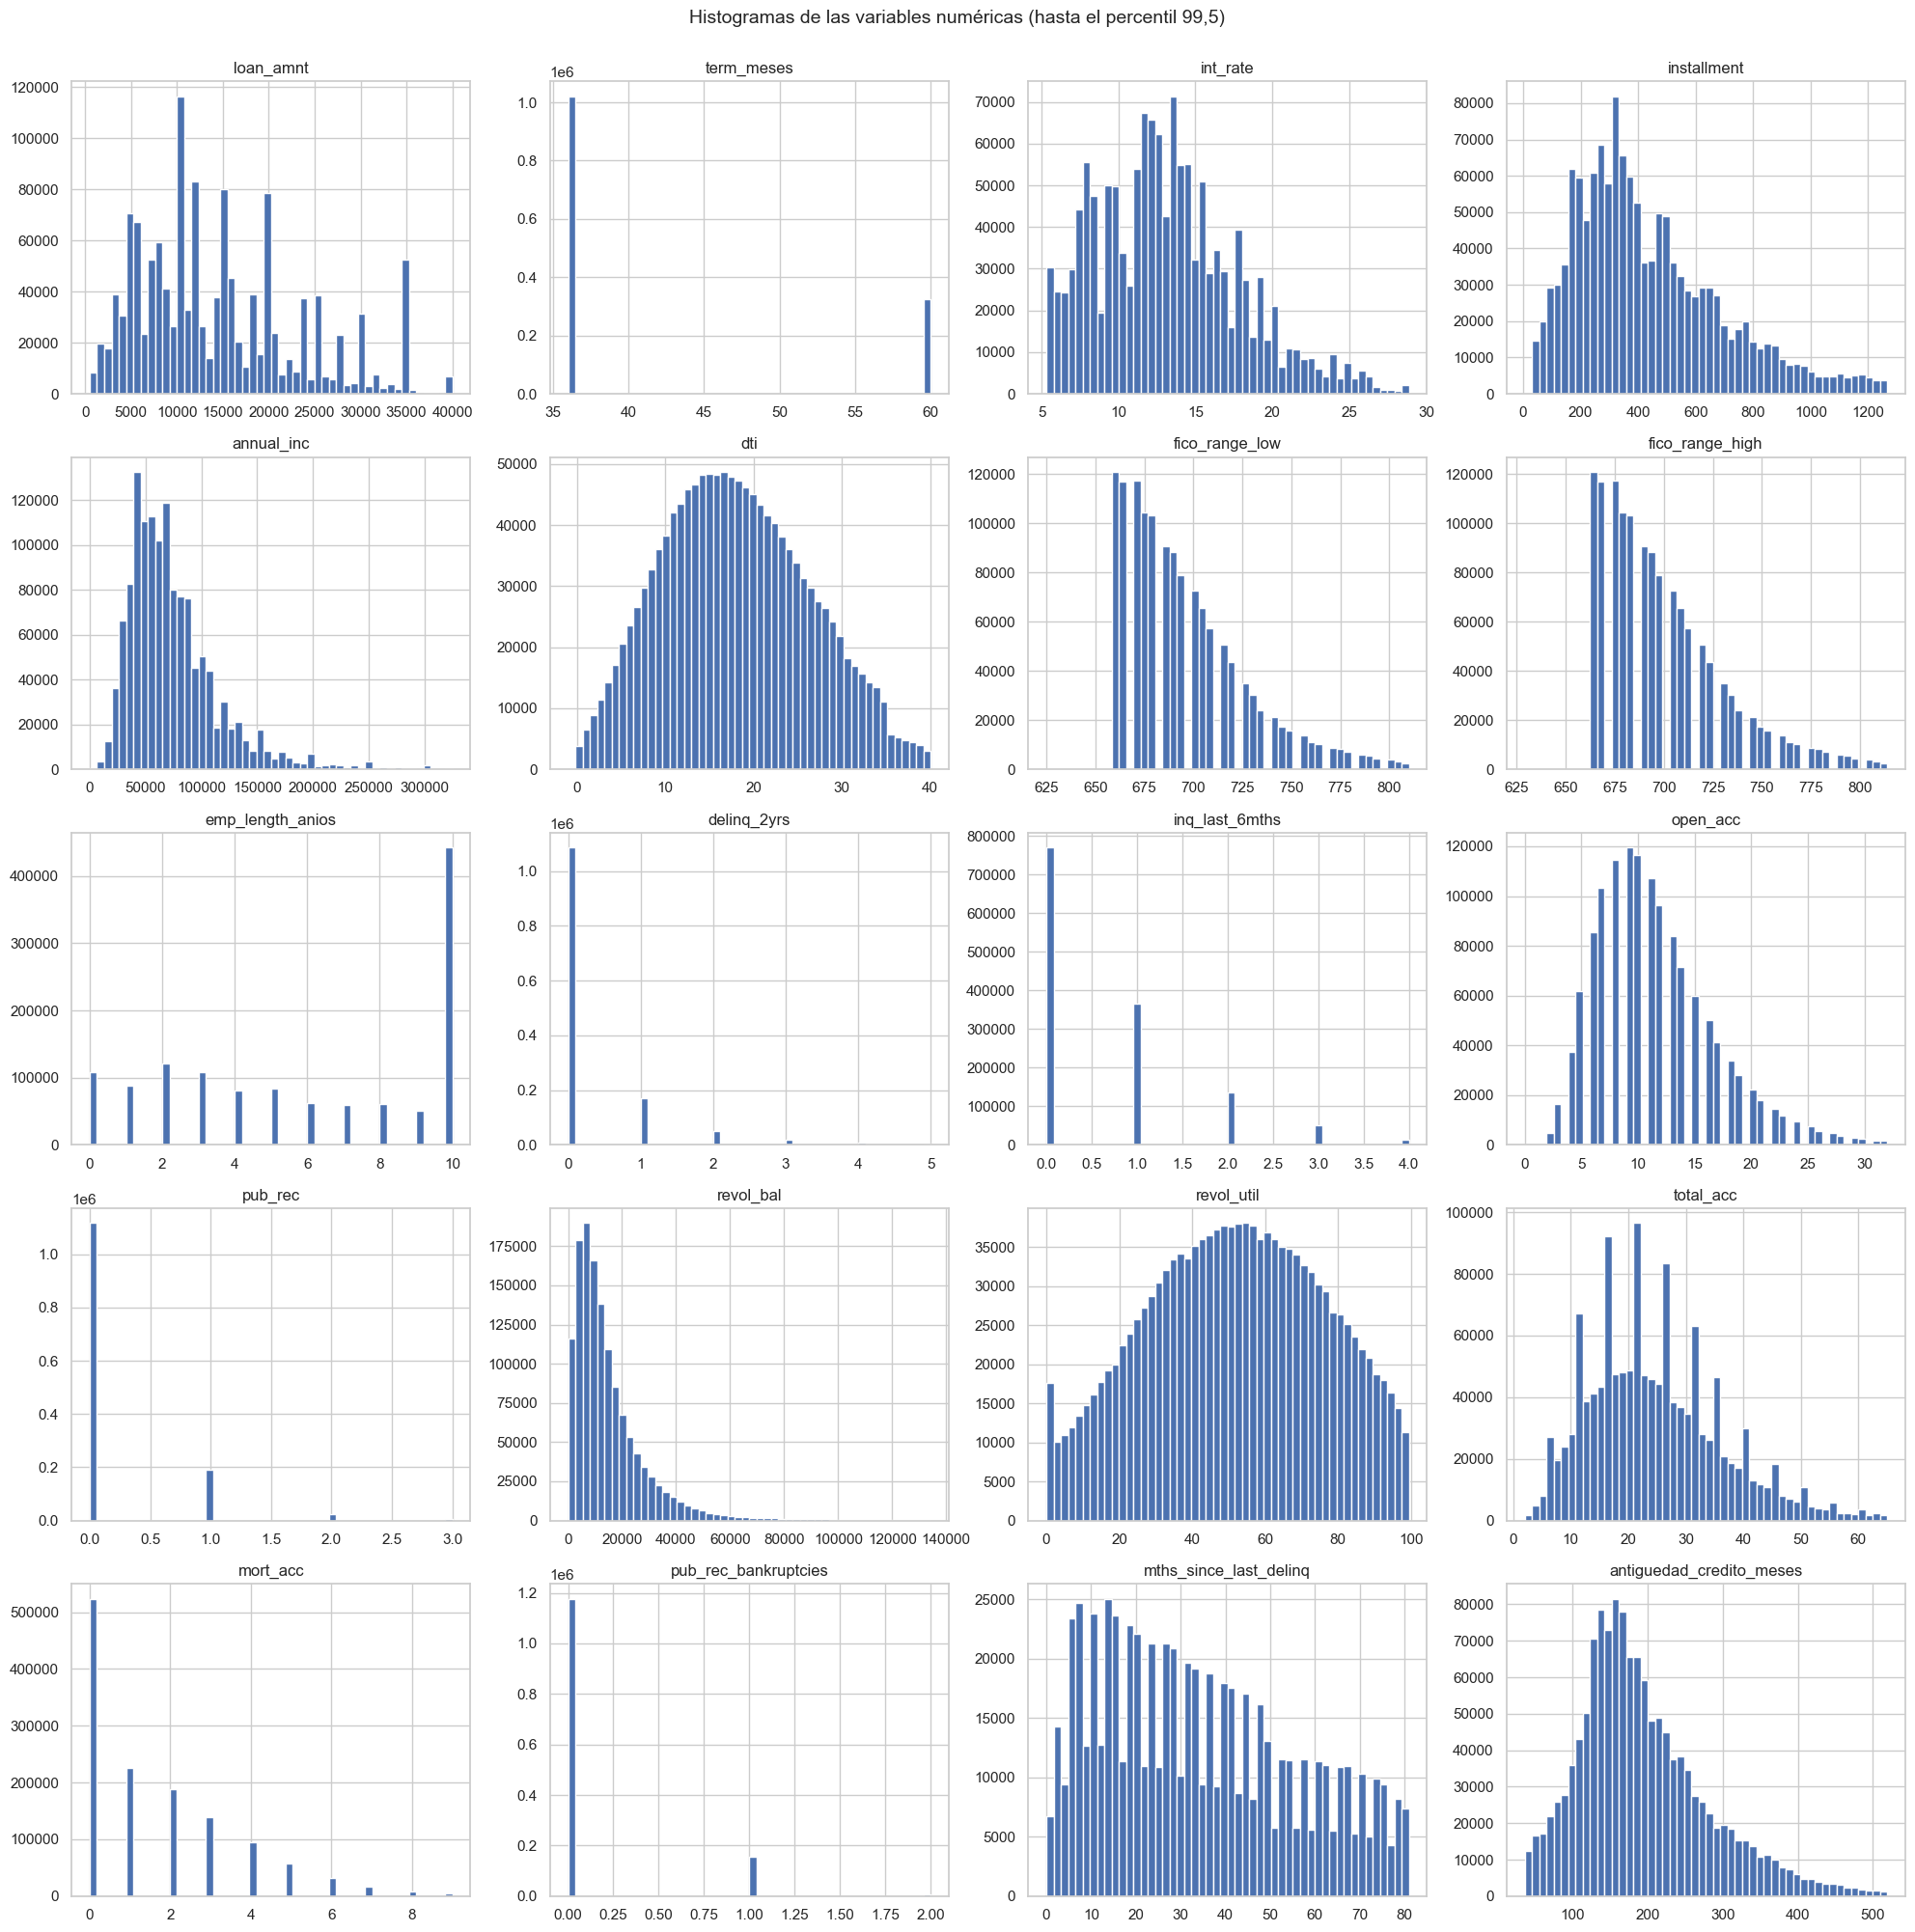

In [11]:
fig, axes = plt.subplots(5, 4, figsize=(20, 20))  # Cuadrícula de 5×4 gráficos
for ax, col in zip(axes.ravel(), cfg.NUMERICAS_EDA):  # Un histograma por variable
    x = df[col].dropna()  # Valores no nulos
    x = x[x <= x.quantile(0.995)]  # Recorta el 0,5 % superior solo para que el gráfico sea legible
    ax.hist(x, bins=50, color="#4C72B0", edgecolor="white")  # Histograma de frecuencias
    ax.set_title(col)  # Título con el nombre de la variable
fig.suptitle("Histogramas de las variables numéricas (hasta el percentil 99,5)", y=1.0, fontsize=14)  # Título general
fig.tight_layout()  # Ajusta los márgenes
guardar_figura(fig, "01_histogramas")  # Exporta la figura
plt.show()  # Muestra la figura

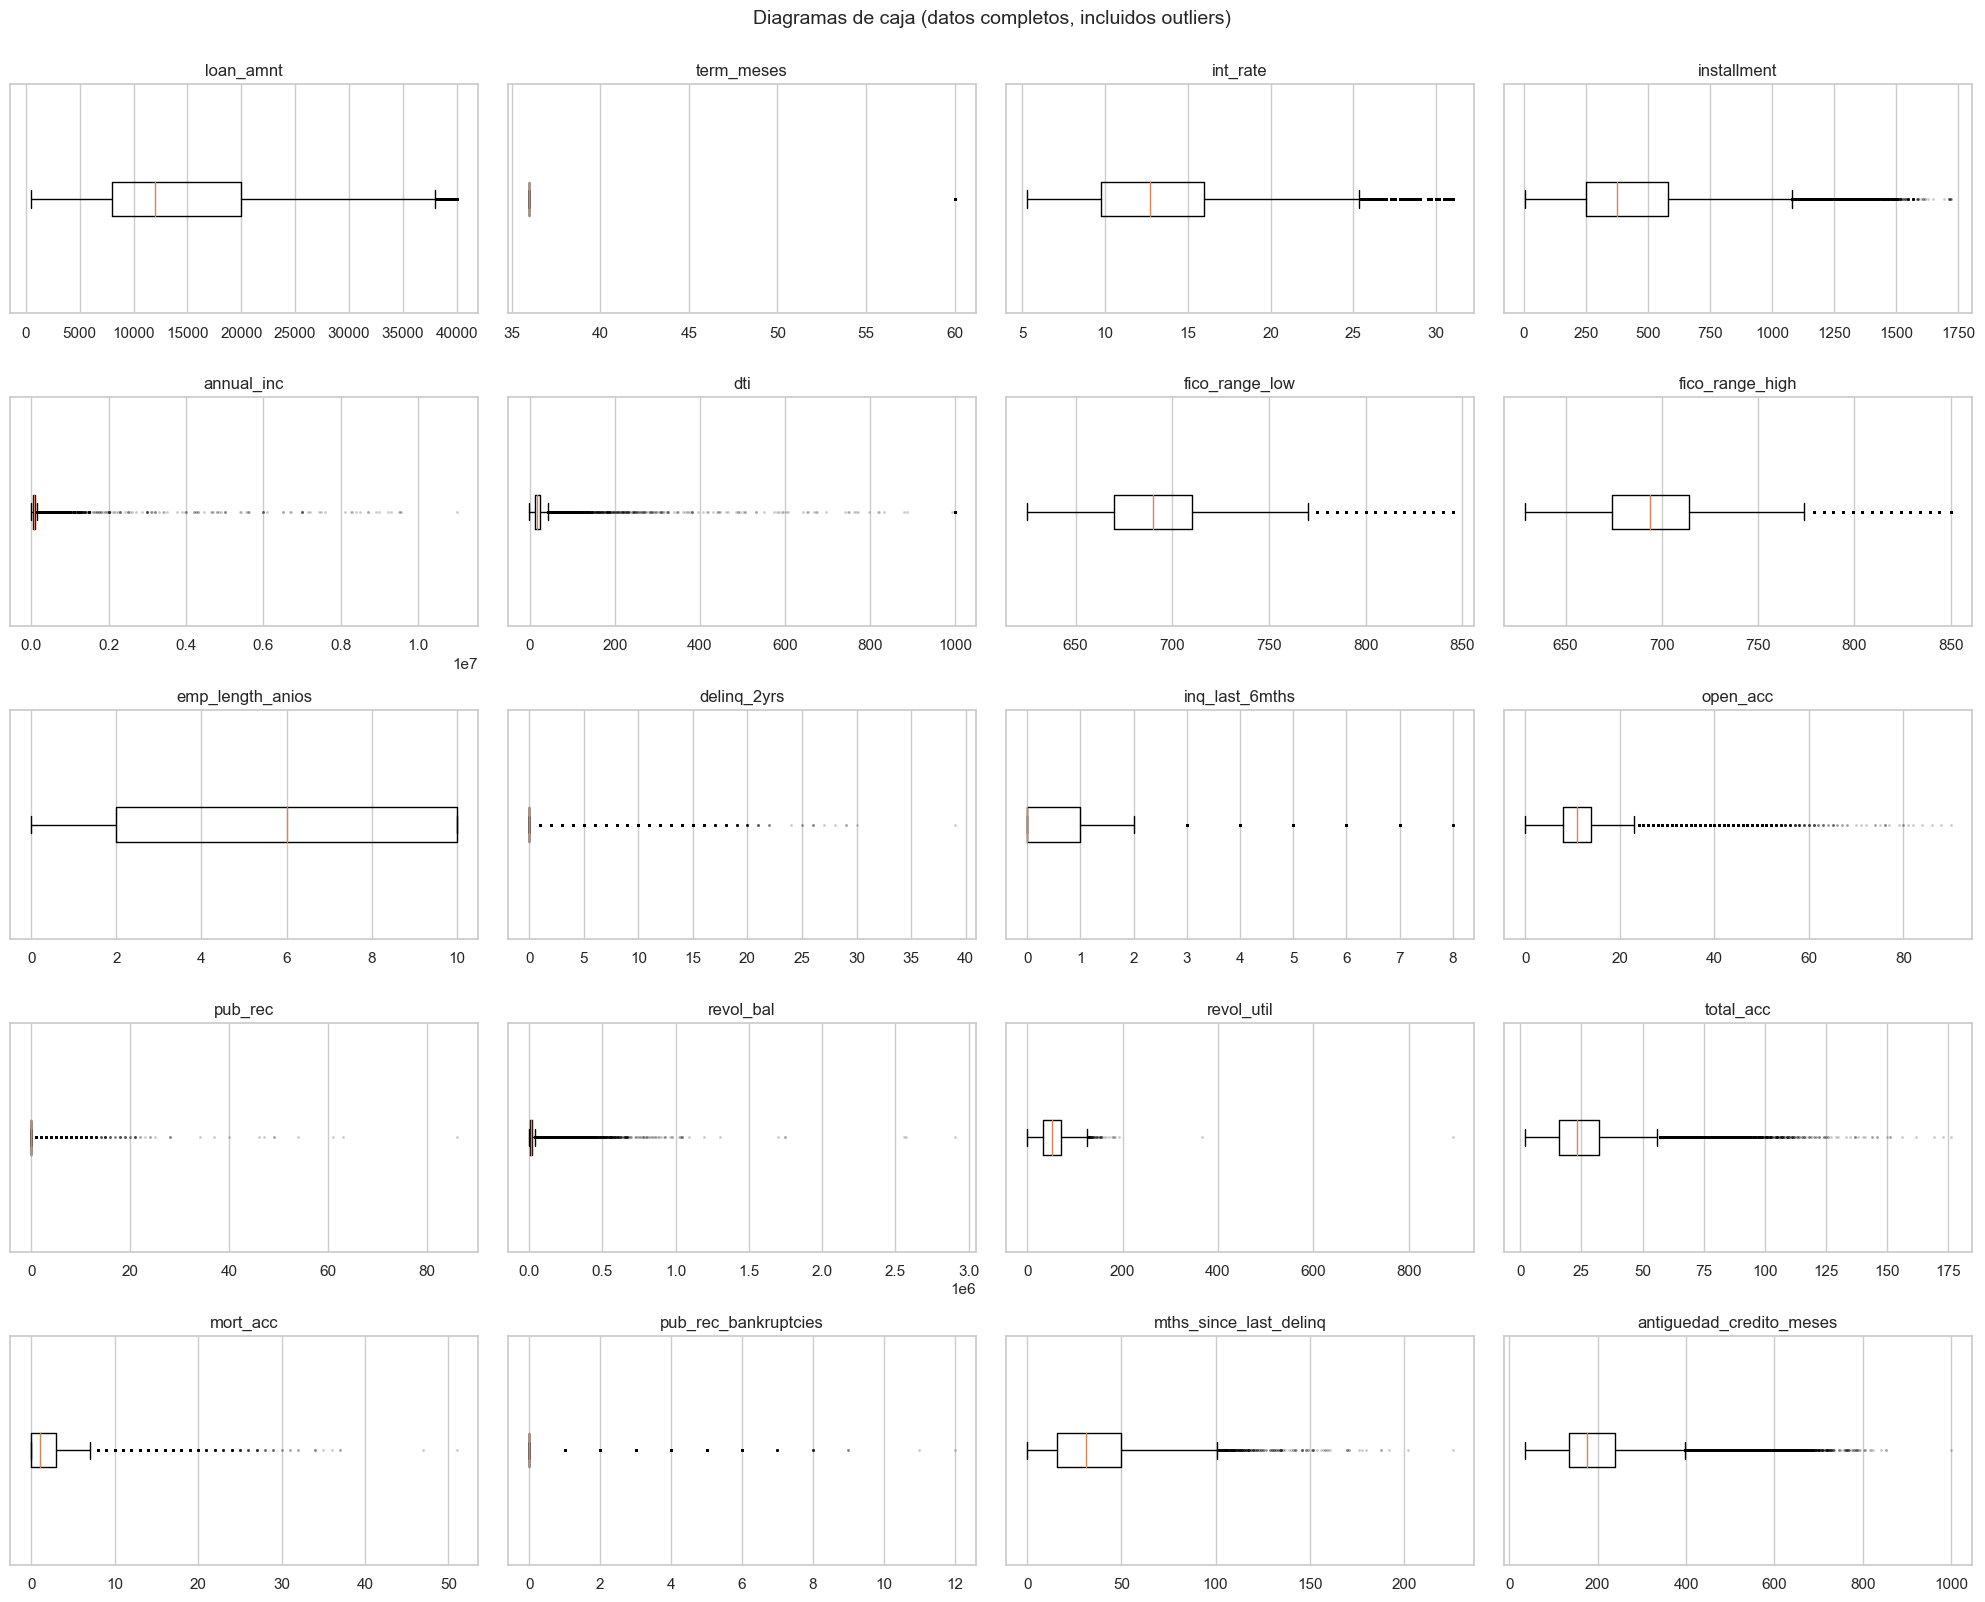

In [12]:
fig, axes = plt.subplots(5, 4, figsize=(20, 16))  # Cuadrícula de 5×4 gráficos
for ax, col in zip(axes.ravel(), cfg.NUMERICAS_EDA):  # Un boxplot por variable
    ax.boxplot(df[col].dropna(), vert=False, flierprops={"markersize": 1, "alpha": 0.2})  # Boxplot horizontal con todos los datos
    ax.set_title(col)  # Título con el nombre de la variable
    ax.set_yticks([])  # Oculta el eje Y (no aporta información)
fig.suptitle("Diagramas de caja (datos completos, incluidos outliers)", y=1.0, fontsize=14)  # Título general
fig.tight_layout()  # Ajusta los márgenes
guardar_figura(fig, "01_boxplots")  # Exporta la figura
plt.show()  # Muestra la figura

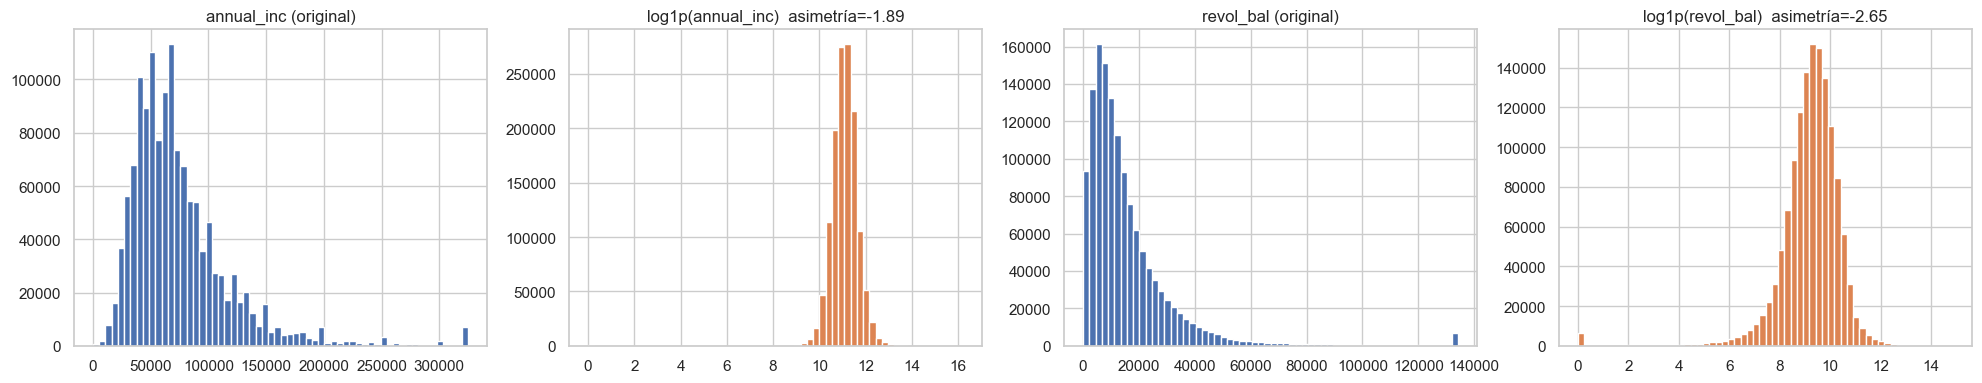

In [13]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4))  # Cuatro gráficos en una fila
for i, col in enumerate(cfg.VARIABLES_LOG):  # Para cada variable muy asimétrica
    axes[2 * i].hist(df[col].dropna().clip(upper=df[col].quantile(0.995)), bins=60)  # Distribución original (recortada)
    axes[2 * i].set_title(f"{col} (original)")  # Título
    axes[2 * i + 1].hist(np.log1p(df[col].dropna().clip(lower=0)), bins=60, color="#DD8452")  # Distribución con log1p
    axes[2 * i + 1].set_title(f"log1p({col})  asimetría={stats.skew(np.log1p(df[col].dropna().clip(lower=0))):.2f}")  # Título con la nueva asimetría
fig.tight_layout()  # Ajusta los márgenes
plt.show()  # Muestra la figura

**Comentario (numéricas).**

* **Ninguna variable es normal** (p < 0.001 en D'Agostino-Pearson para todas; con 1,3 M de
  observaciones cualquier desviación es significativa). Las asimetrías más extremas son
  `annual_inc` (46, curtosis ≈ 4.800), `dti` (27), `revol_bal` (13,7) y `pub_rec` (11,6).
  `log1p` reduce la asimetría de `annual_inc` (46 → −1,9) y `revol_bal` (13,7 → −2,6; la cola
  izquierda restante se debe a los ceros), por lo que se aplicará en el preprocesamiento (ayuda a la regresión logística, LinearSVC y Naive Bayes;
  a los árboles les es indiferente). Box-Cox no es aplicable directamente porque hay ceros.
* **Outliers (regla IQR):** `delinq_2yrs` (19 %), `pub_rec` (17 %) y `pub_rec_bankruptcies`
  (12 %) tienen IQR = 0, así que cualquier valor distinto de 0 se marca como atípico: no son
  errores sino eventos raros. `term_meses` solo toma 36 o 60. Sí hay valores **implausibles**:
  `dti` = 999, `revol_util` = 892 %, `annual_inc` = 11 M. Se conservan (no se permite
  eliminar filas y los árboles son robustos); el escalado estándar los amortigua para los
  modelos lineales.
* **Faltantes:** solo `mths_since_last_delinq` supera el umbral del 30 % (50,5 %); el resto
  tiene < 6 %. Pese a superar el umbral **no se elimina**: su nulo significa "nunca tuvo
  morosidad" y es informativo (ver sección de faltantes) → indicador + imputación.

### Variables categóricas

In [14]:
tablas_cat = {}  # Diccionario variable → tabla de frecuencias
for col in cfg.CATEGORICAS_EDA:  # Recorre cada variable categórica
    t = df[col].value_counts(dropna=False).to_frame("frecuencia")  # Frecuencia absoluta (incluye nulos)
    t["porcentaje"] = 100 * t["frecuencia"] / len(df)  # Frecuencia relativa
    t["rara_<1%"] = t["porcentaje"] < 100 * cfg.UMBRAL_CATEGORIA_RARA  # Marca categorías con menos del 1 %
    tablas_cat[col] = t  # Guarda la tabla
    print(f"\n=== {col}: {len(t)} categorías, {int(t['rara_<1%'].sum())} raras, nulos = {100 * df[col].isna().mean():.2f} %")  # Resumen
    display(t.head(15))  # Muestra hasta 15 categorías


=== grade: 7 categorías, 1 raras, nulos = 0.00 %


,frecuencia,porcentaje,rara_<1%
grade,,,
B,392741,29.1933,False
C,381686,28.3716,False
A,235090,17.4748,False
D,200953,14.9373,False
E,93650,6.9612,False
F,32058,2.3829,False
G,9132,0.6788,True



=== sub_grade: 35 categorías, 10 raras, nulos = 0.00 %


,frecuencia,porcentaje,rara_<1%
sub_grade,,,
C1,85494,6.3550,False
B4,83199,6.1844,False
B5,82538,6.1352,False
B3,81827,6.0824,False
C2,79213,5.8881,False
C3,74998,5.5748,False
C4,74421,5.5319,False
B2,74024,5.5024,False
B1,71153,5.2890,False



=== home_ownership: 6 categorías, 3 raras, nulos = 0.00 %


...

,frecuencia,porcentaje,rara_<1%
addr_state,,,
CA,196528,14.6084,False
TX,110169,8.1891,False
NY,109842,8.1648,False
FL,95606,7.1066,False
IL,51720,3.8445,False
NJ,48449,3.6013,False
PA,45522,3.3838,False
OH,43842,3.2589,False
GA,43376,3.2242,False



=== initial_list_status: 2 categorías, 0 raras, nulos = 0.00 %


,frecuencia,porcentaje,rara_<1%
initial_list_status,,,
w,784010,58.2773,False
f,561300,41.7227,False



=== application_type: 2 categorías, 0 raras, nulos = 0.00 %


,frecuencia,porcentaje,rara_<1%
application_type,,,
Individual,1319510,98.0822,False
Joint App,25800,1.9178,False


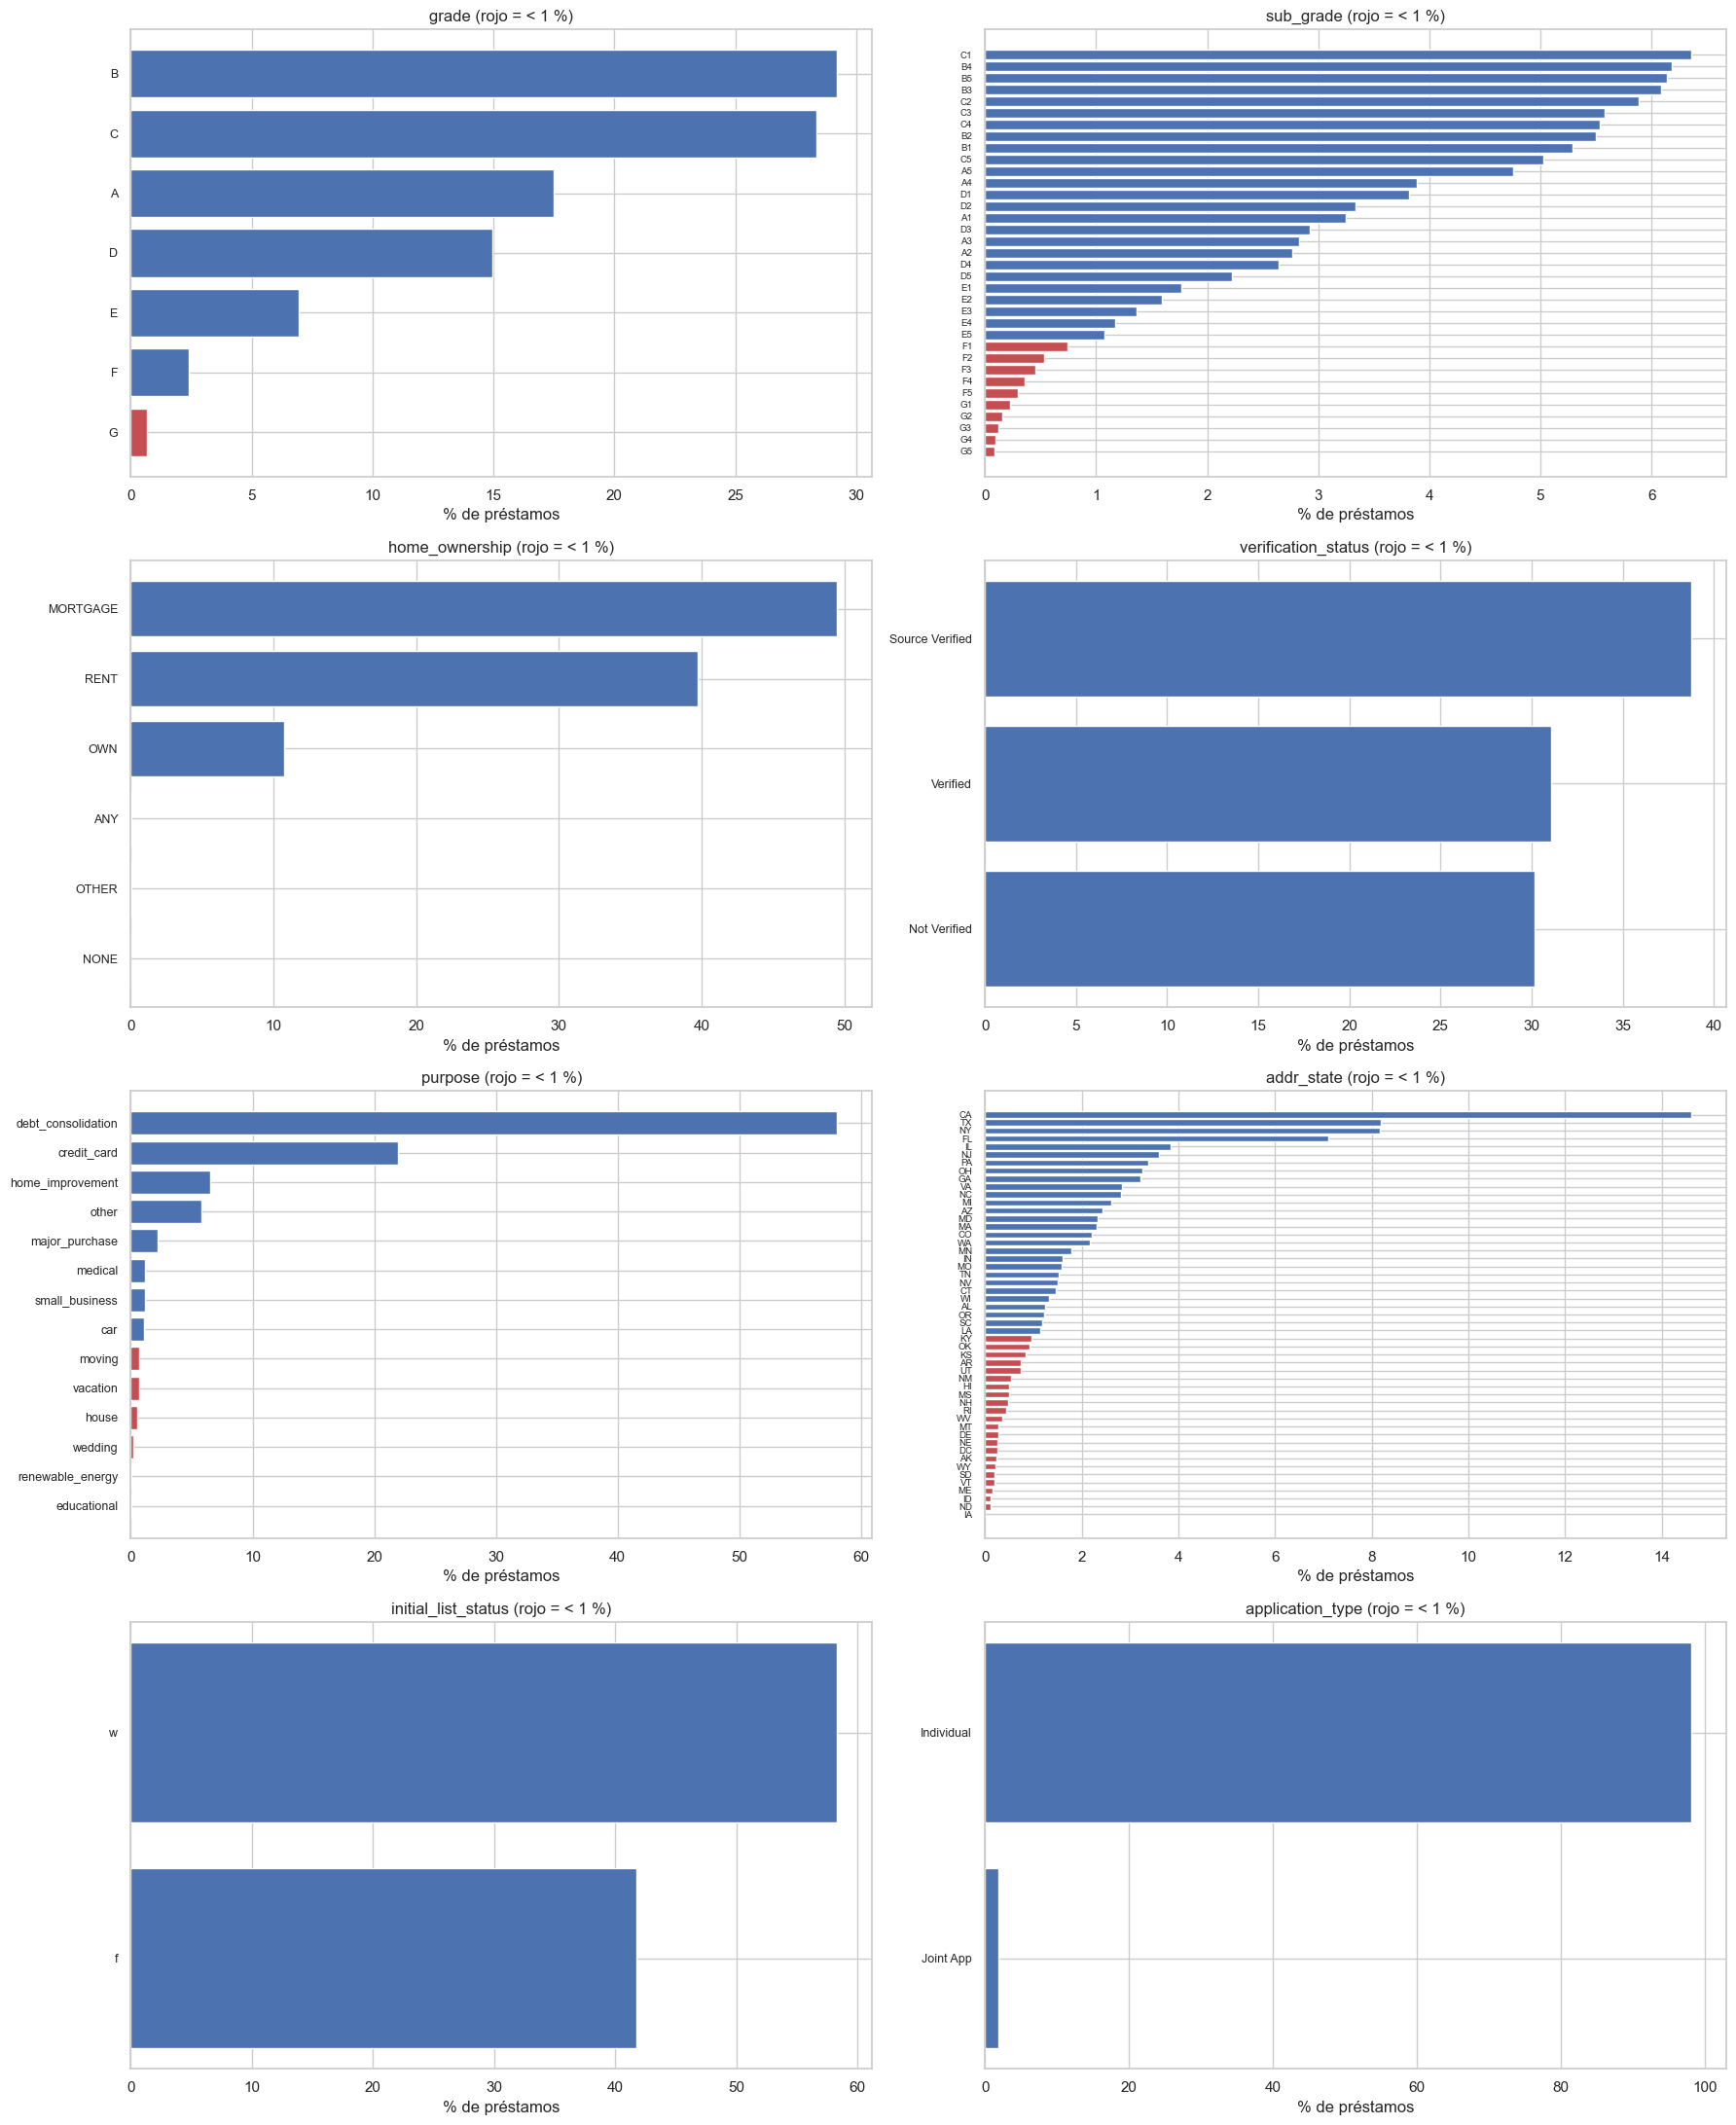

In [15]:
fig, axes = plt.subplots(4, 2, figsize=(18, 22))  # Cuadrícula de 4×2 gráficos
for ax, col in zip(axes.ravel(), cfg.CATEGORICAS_EDA):  # Un gráfico de barras por variable
    t = tablas_cat[col]["porcentaje"].sort_values()  # Porcentajes ordenados
    colores = ["#C44E52" if p < 1 else "#4C72B0" for p in t.values]  # Rojo para categorías raras
    ax.barh(t.index.astype(str), t.values, color=colores)  # Barras horizontales
    ax.set_title(f"{col} (rojo = < 1 %)")  # Título
    ax.set_xlabel("% de préstamos")  # Etiqueta del eje X
    ax.tick_params(axis="y", labelsize=7 if len(t) > 20 else 9)  # Letra más pequeña si hay muchas categorías
fig.tight_layout()  # Ajusta los márgenes
guardar_figura(fig, "01_barras_categoricas")  # Exporta la figura
plt.show()  # Muestra la figura

**Comentario (categóricas).** No hay nulos en ninguna categórica de trabajo. Categorías con
menos del 1 %: `grade` G (0,68 %), 10 sub-calificaciones, `home_ownership` ANY/OTHER/NONE
(478 préstamos en total, **significado redundante**: las tres indican "otra tenencia"),
seis propósitos (`moving`, `vacation`, `house`, `wedding`, `renewable_energy`, `educational`)
y 23 estados. Decisión: agrupar en `OTROS` toda categoría con < 1 % **en train** (se aprende
solo con train para no filtrar información de test). `sub_grade` es una partición fina de
`grade` (redundante) y `application_type` está muy concentrada (98 % individual).

### Variable objetivo (`default`)

,n,%
0 = Fully Paid,1076751,80.0374
1 = Charged Off,268559,19.9626


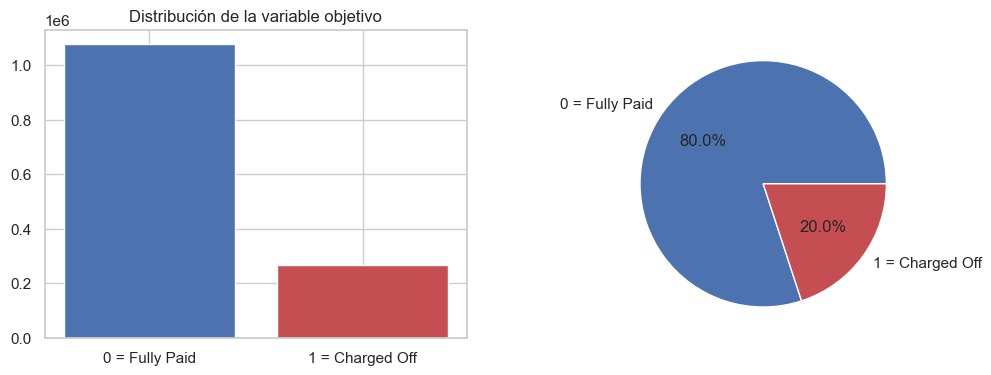

Razón de desbalance: 4.01 : 1


In [16]:
clases = df[cfg.COL_TARGET].value_counts().sort_index().to_frame("n")  # Conteo por clase
clases["%"] = 100 * clases["n"] / clases["n"].sum()  # Porcentaje por clase
clases.index = ["0 = Fully Paid", "1 = Charged Off"]  # Nombres descriptivos
display(clases)  # Muestra la tabla
fig, axes = plt.subplots(1, 2, figsize=(12, 4))  # Dos gráficos lado a lado
axes[0].bar(clases.index, clases["n"], color=["#4C72B0", "#C44E52"])  # Gráfico de barras
axes[0].set_title("Distribución de la variable objetivo")  # Título
axes[1].pie(clases["n"], labels=clases.index, autopct="%1.1f%%", colors=["#4C72B0", "#C44E52"])  # Gráfico de pastel
guardar_figura(fig, "01_target")  # Exporta la figura
plt.show()  # Muestra la figura
print(f"Razón de desbalance: {clases['n'].iloc[0] / clases['n'].iloc[1]:.2f} : 1")  # Relación entre clases

**Comentario.** El 80,0 % de los préstamos se pagó y el 20,0 % terminó en default
(desbalance moderado 4:1). Implicaciones: (1) la partición debe ser **estratificada**;
(2) la *accuracy* es engañosa (un modelo trivial obtiene 0,80), por lo que el criterio de
selección es el **AUC ROC** y se reportan también precisión, recall, F1 y AUC-PR; (3) el
umbral 0,5 tenderá a predecir casi siempre "pagado", así que para las decisiones (McNemar,
F1) se optimiza el umbral **con datos de train**. No se aplica sobremuestreo: con 269 mil
defaults la clase minoritaria está bien representada.

## 2.4 Análisis bidimensional

### Numéricas vs. `default`

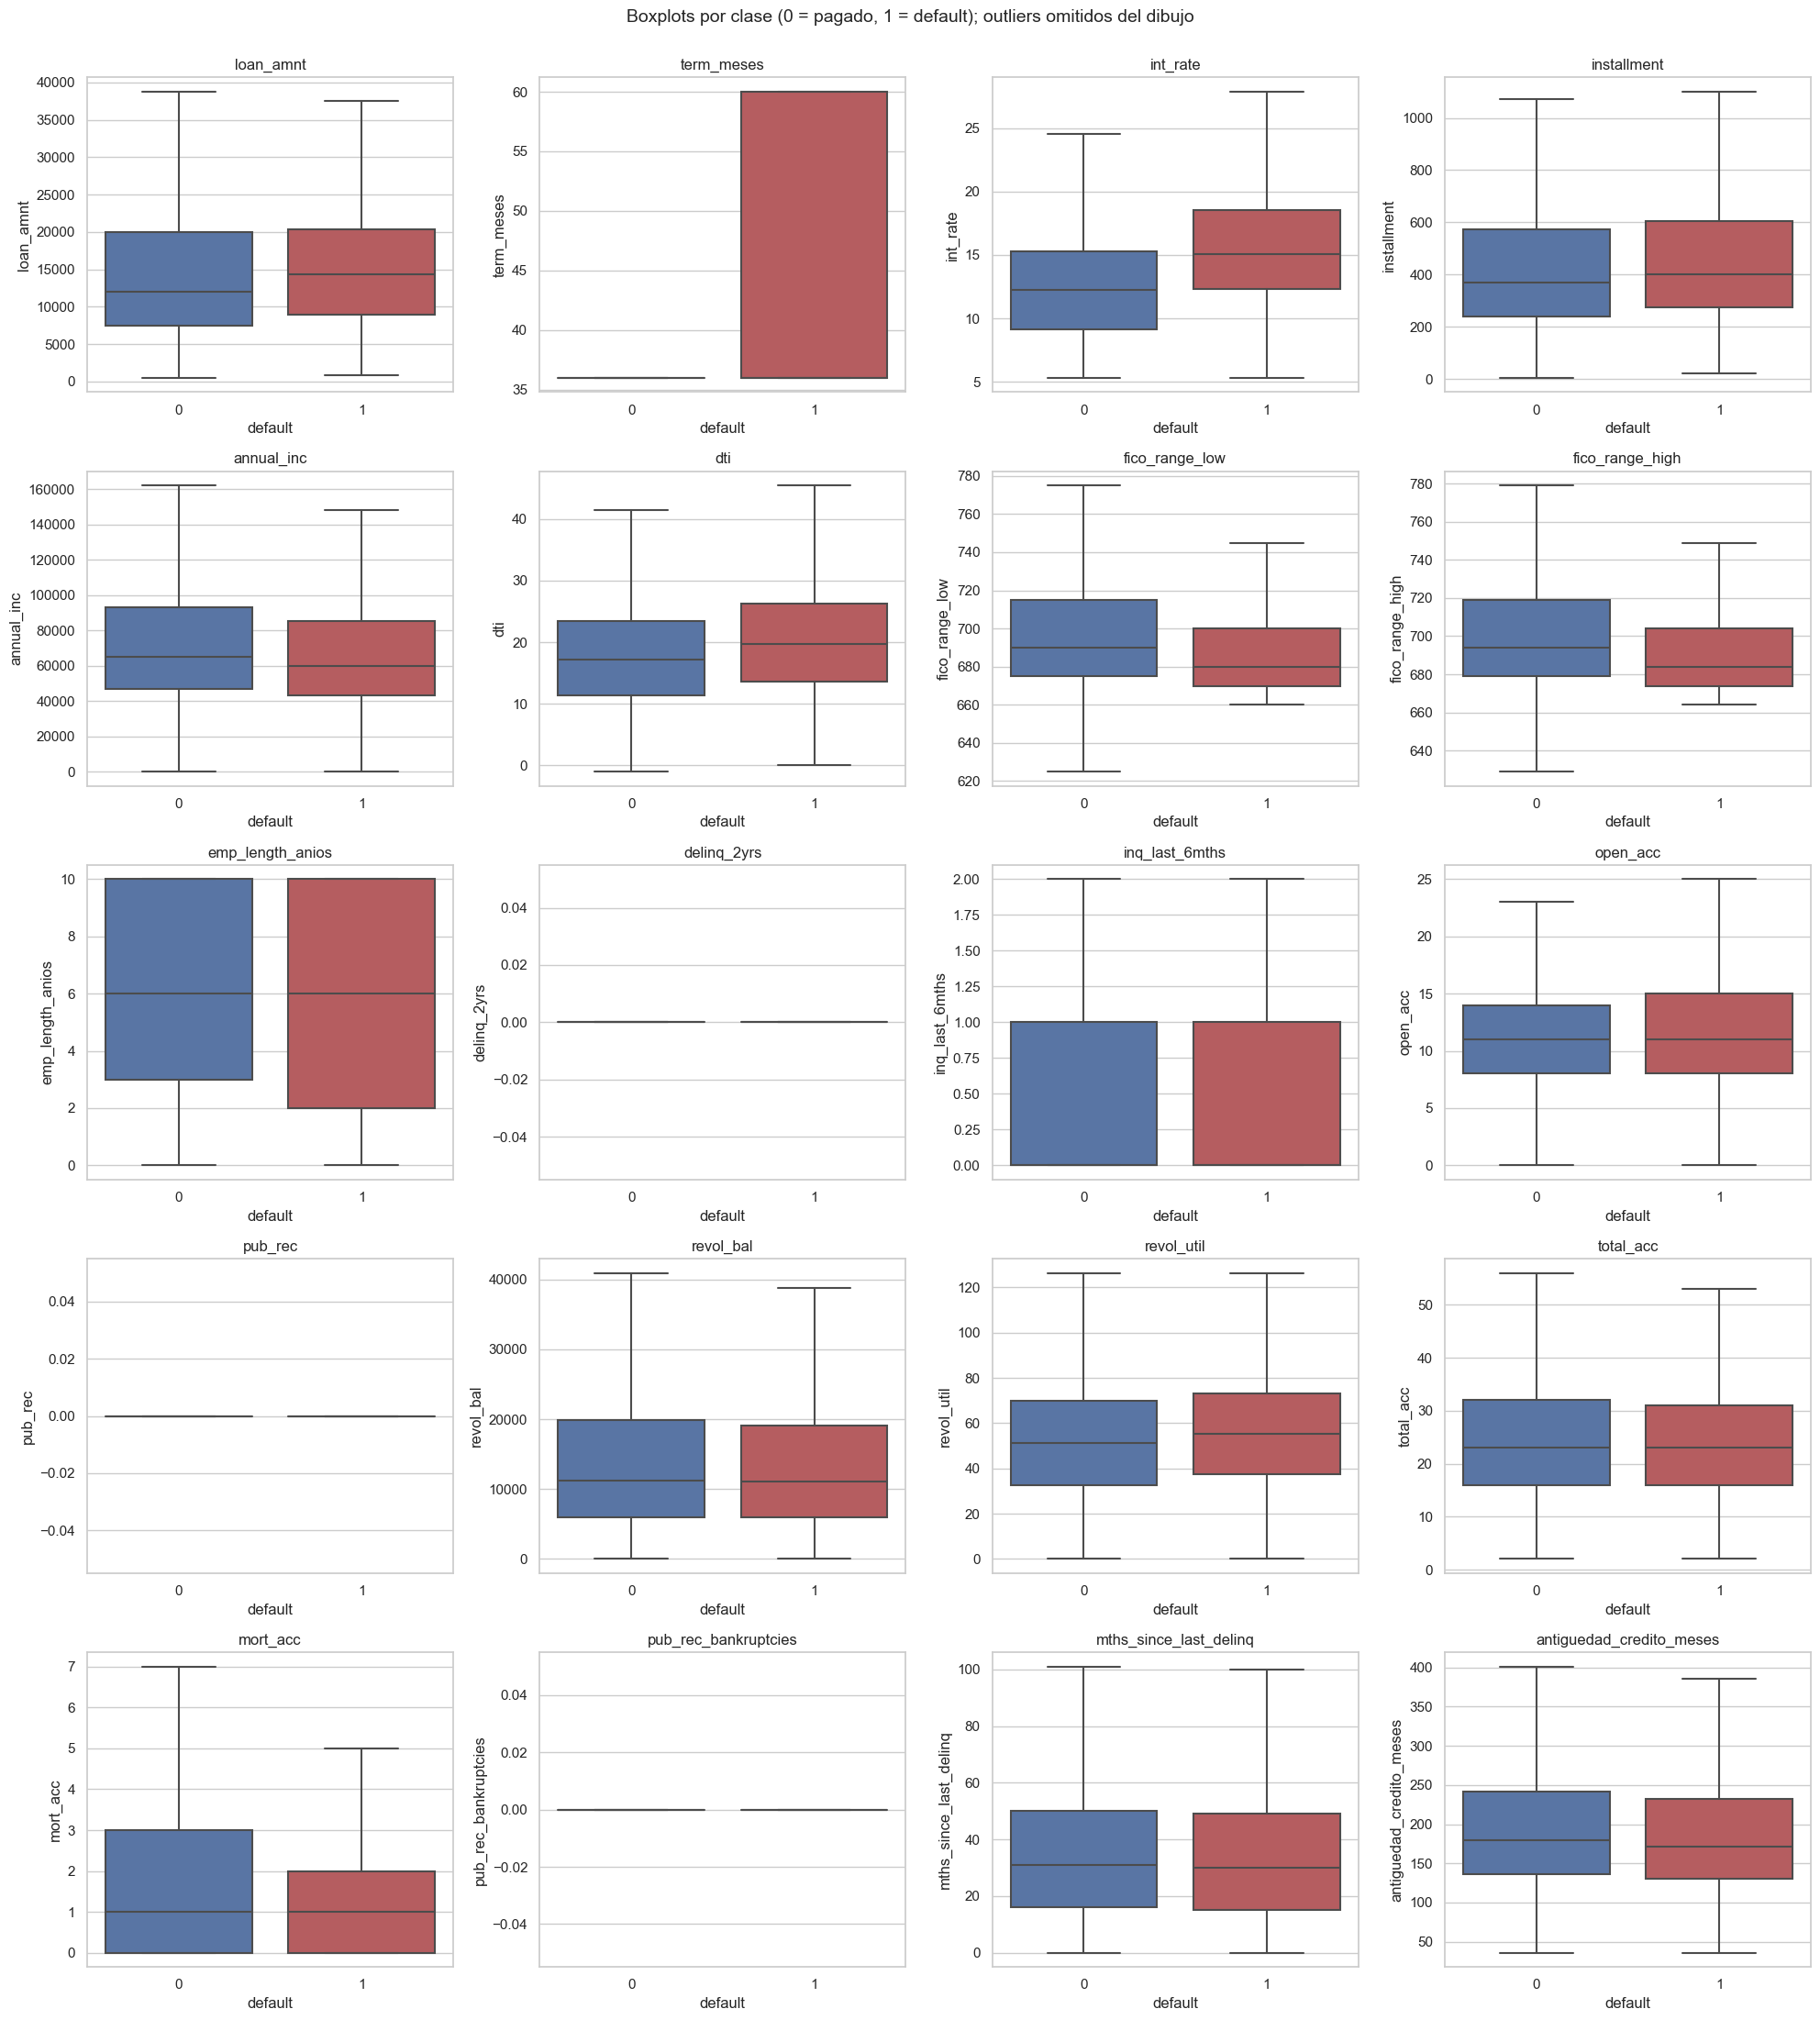

In [17]:
fig, axes = plt.subplots(5, 4, figsize=(20, 22))  # Cuadrícula de 5×4 gráficos
for ax, col in zip(axes.ravel(), cfg.NUMERICAS_EDA):  # Un boxplot comparativo por variable
    sns.boxplot(data=df, x=cfg.COL_TARGET, y=col, ax=ax, showfliers=False,  # Boxplot por clase (sin dibujar outliers para legibilidad)
                palette=["#4C72B0", "#C44E52"])  # Colores por clase
    ax.set_title(col)  # Título
fig.suptitle("Boxplots por clase (0 = pagado, 1 = default); outliers omitidos del dibujo", y=1.0, fontsize=14)  # Título general
fig.tight_layout()  # Ajusta los márgenes
guardar_figura(fig, "01_boxplots_por_clase")  # Exporta la figura
plt.show()  # Muestra la figura

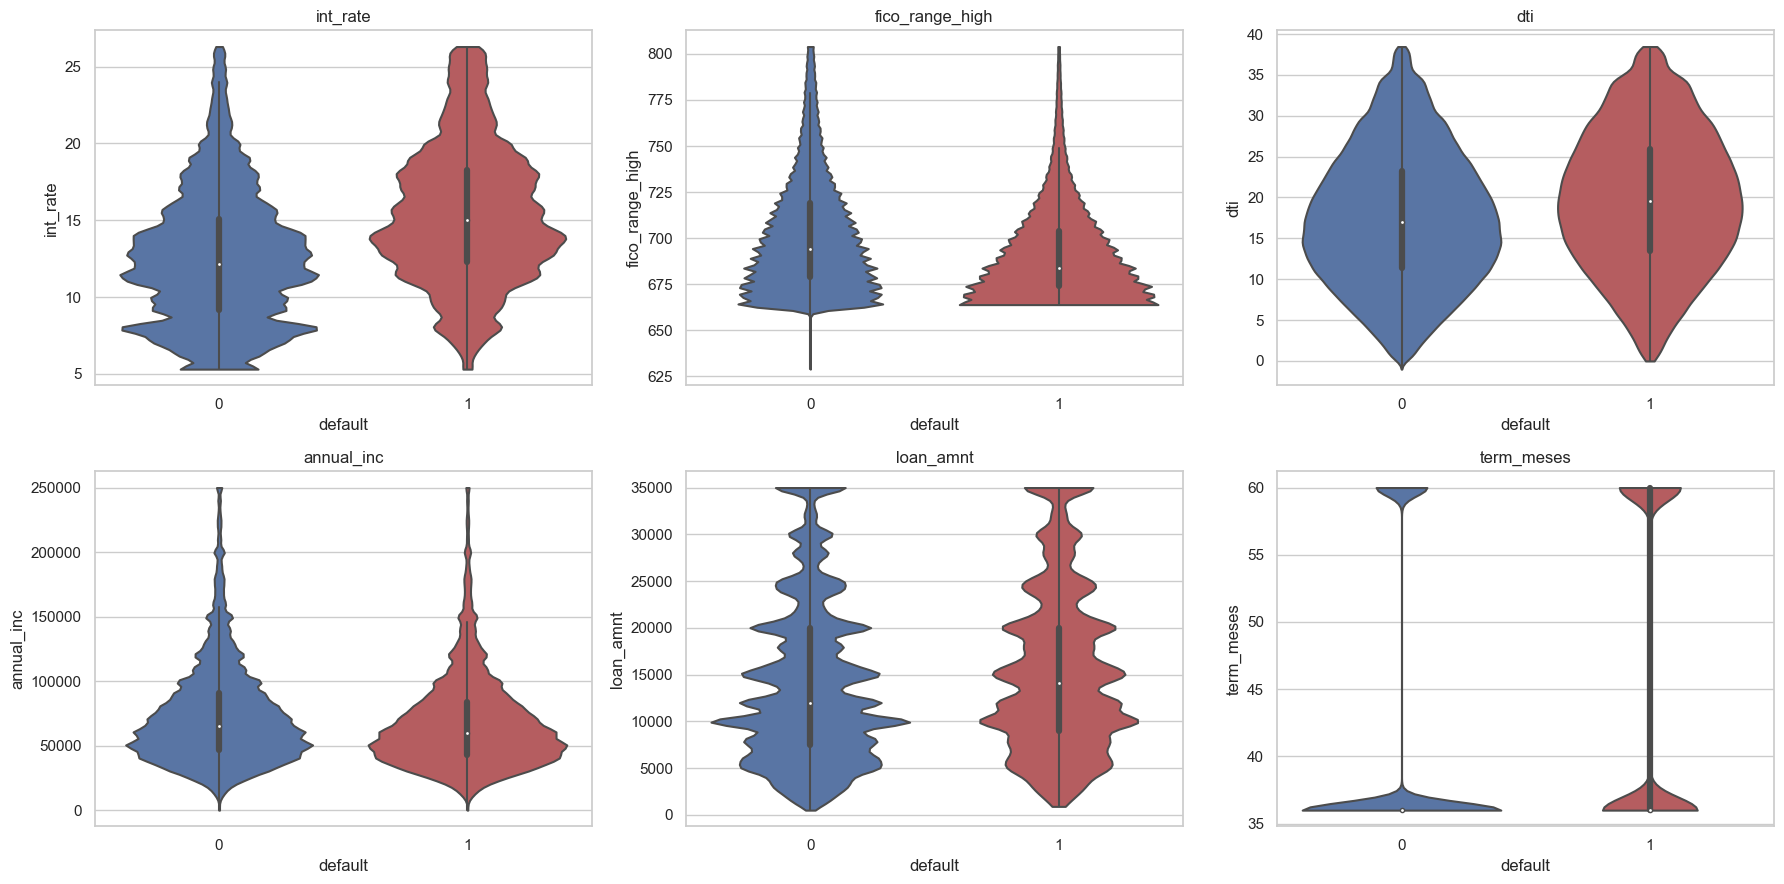

In [18]:
claves = ["int_rate", "fico_range_high", "dti", "annual_inc", "loan_amnt", "term_meses"]  # Variables clave para violines
fig, axes = plt.subplots(2, 3, figsize=(18, 9))  # Cuadrícula de 2×3
for ax, col in zip(axes.ravel(), claves):  # Un violin plot por variable
    datos = df[[col, cfg.COL_TARGET]].dropna()  # Datos sin nulos
    datos = datos[datos[col] <= datos[col].quantile(0.99)]  # Recorta el 1 % superior solo para visualizar
    sns.violinplot(data=datos, x=cfg.COL_TARGET, y=col, ax=ax,  # Violin plot por clase
                   palette=["#4C72B0", "#C44E52"], cut=0)  # Colores y sin extrapolar la densidad
    ax.set_title(col)  # Título
fig.tight_layout()  # Ajusta los márgenes
guardar_figura(fig, "01_violines")  # Exporta la figura
plt.show()  # Muestra la figura

In [19]:
filas = []  # Lista de resultados por variable
for col in cfg.NUMERICAS_EDA:  # Recorre cada variable numérica
    d = df[[col, cfg.COL_TARGET]].dropna()  # Pares sin nulos
    x0 = d.loc[d[cfg.COL_TARGET] == 0, col]  # Valores de la clase 0
    x1 = d.loc[d[cfg.COL_TARGET] == 1, col]  # Valores de la clase 1
    t_stat, p_t = stats.ttest_ind(x1, x0, equal_var=False)  # Prueba t de Welch (varianzas distintas)
    u_stat, p_u = stats.mannwhitneyu(x1, x0, alternative="two-sided")  # Prueba de Mann-Whitney (no paramétrica)
    r_pb, p_pb = stats.pointbiserialr(d[cfg.COL_TARGET], d[col])  # Correlación punto-biserial
    filas.append({  # Guarda el resultado
        "media_0": x0.mean(), "media_1": x1.mean(), "dif_medias": x1.mean() - x0.mean(),  # Medias y diferencia
        "mediana_0": x0.median(), "mediana_1": x1.median(),  # Medianas por clase
        "p_t_welch": p_t, "p_mann_whitney": p_u,  # Valores p de ambas pruebas
        "r_punto_biserial": r_pb, "abs_r": abs(r_pb),  # Correlación y su valor absoluto
    })
biv_num = pd.DataFrame(filas, index=cfg.NUMERICAS_EDA).sort_values("abs_r", ascending=False)  # Ordena por fuerza de asociación
biv_num  # Muestra la tabla

,media_0,media_1,dif_medias,mediana_0,mediana_1,p_t_welch,p_mann_whitney,r_punto_biserial,abs_r
int_rate,12.6233,15.7107,3.0874,12.2300,15.0500,0.0000,0.0000,0.2588,0.2588
term_meses,40.8871,45.4108,4.5237,36.0000,36.0000,0.0000,0.0000,0.1761,0.1761
fico_range_low,698.2639,687.8501,-10.4138,690.0000,680.0000,0.0000,0.0000,-0.1307,0.1307
fico_range_high,702.2641,691.8502,-10.4139,694.0000,684.0000,0.0000,0.0000,-0.1307,0.1307
dti,17.8116,20.1712,2.3596,17.1100,19.7600,0.0000,0.0000,0.0845,0.0845
mort_acc,1.7465,1.3710,-0.3754,1.0000,1.0000,0.0000,0.0000,-0.0753,0.0753
loan_amnt,"14,134.3698","15,565.0554","1,430.6856","12,000.0000","14,350.0000",0.0000,0.0000,0.0656,0.0656
inq_last_6mths,0.6244,0.7780,0.1536,0.0000,0.0000,0.0000,0.0000,0.0655,0.0655
revol_util,51.0747,54.7584,3.6838,51.3000,55.5000,0.0000,0.0000,0.0600,0.0600
installment,431.3232,465.1480,33.8248,368.2600,402.8300,0.0000,0.0000,0.0517,0.0517


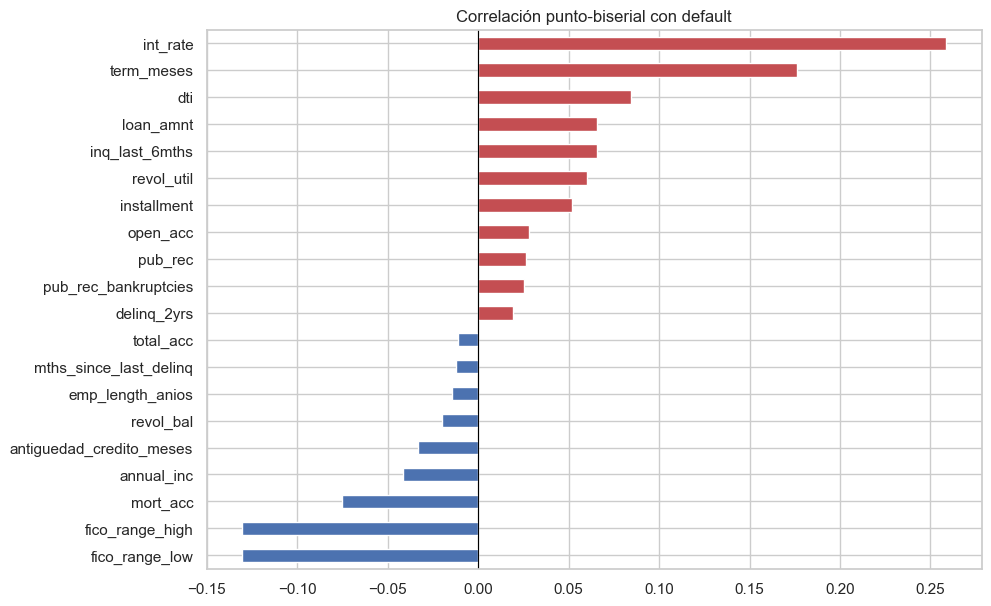

In [20]:
fig, ax = plt.subplots(figsize=(10, 7))  # Figura para la correlación punto-biserial
biv_num["r_punto_biserial"].sort_values().plot.barh(ax=ax, color=["#C44E52" if v > 0 else "#4C72B0" for v in biv_num["r_punto_biserial"].sort_values()])  # Barras por signo
ax.set_title("Correlación punto-biserial con default")  # Título
ax.axvline(0, color="black", lw=0.8)  # Línea de referencia en cero
guardar_figura(fig, "01_punto_biserial")  # Exporta la figura
plt.show()  # Muestra la figura

**Comentario.** Todas las diferencias de medias son significativas (p < 0.001 en Welch y
Mann-Whitney), algo esperable con 1,3 M de filas; por eso se ordena por la **magnitud** de la
correlación punto-biserial. Las numéricas más asociadas al default son `int_rate`
(r = 0,26; media 15,7 % en defaults vs 12,6 %), `term_meses` (0,18: los préstamos a 60
meses son más riesgosos), `fico_range_high` (−0,13; 10 puntos menos en defaults), `dti`
(0,08), `mort_acc` (−0,08), `loan_amnt`, `inq_last_6mths` y `revol_util` (≈ 0,06). El
resto tiene |r| < 0,05: aportan poco de forma individual, aunque pueden interactuar en
modelos no lineales.

### Categóricas vs. `default`

In [21]:
def v_cramer(x, y):  # Coeficiente V de Cramér entre dos variables categóricas
    tabla = pd.crosstab(x, y)  # Tabla de contingencia
    chi2 = stats.chi2_contingency(tabla, correction=False)[0]  # Estadístico chi-cuadrado
    n = tabla.values.sum()  # Total de observaciones
    k = min(tabla.shape) - 1  # Grados de libertad mínimos
    return np.sqrt(chi2 / (n * k)) if k > 0 else 0.0  # V = sqrt(χ² / (n·k))

filas = []  # Resultados de la prueba chi-cuadrado
tasas_cat = {}  # Tasa de default por categoría
for col in cfg.CATEGORICAS_EDA:  # Recorre cada categórica
    x = df[col].fillna(cfg.CATEGORIA_FALTANTE)  # Nulos como categoría propia
    tabla = pd.crosstab(x, df[cfg.COL_TARGET])  # Tabla de contingencia
    chi2, p, gl, _ = stats.chi2_contingency(tabla)  # Prueba de independencia
    tasa = pd.crosstab(x, df[cfg.COL_TARGET], normalize="index")[1].sort_values(ascending=False)  # Proporción de default por categoría
    tasas_cat[col] = tasa  # Guarda las tasas
    filas.append({"chi2": chi2, "gl": gl, "p_valor": p, "V_cramer": v_cramer(x, df[cfg.COL_TARGET]),  # Estadísticos
                  "categoria_mayor_tasa": tasa.index[0], "mayor_tasa": tasa.iloc[0],  # Categoría más riesgosa
                  "categoria_menor_tasa": tasa.index[-1], "menor_tasa": tasa.iloc[-1]})  # Categoría menos riesgosa
biv_cat = pd.DataFrame(filas, index=cfg.CATEGORICAS_EDA).sort_values("V_cramer", ascending=False)  # Tabla ordenada
biv_cat  # Muestra la tabla

,chi2,gl,p_valor,V_cramer,categoria_mayor_tasa,mayor_tasa,categoria_menor_tasa,menor_tasa
sub_grade,"96,525.3877",34,0.0000,0.2679,G5,0.5360,A1,0.0322
grade,"92,284.2511",6,0.0000,0.2619,G,0.4993,A,0.0604
verification_status,"11,387.4390",2,0.0000,0.0920,Verified,0.2385,Not Verified,0.1467
home_ownership,"6,743.1900",5,0.0000,0.0708,RENT,0.2322,NONE,0.1458
purpose,"4,144.1960",13,0.0000,0.0555,small_business,0.2971,wedding,0.1216
addr_state,"3,403.5833",50,0.0000,0.0503,MS,0.2608,DC,0.1321
application_type,352.1009,1,0.0000,0.0162,Joint App,0.2459,Individual,0.1987
initial_list_status,71.3174,1,0.0000,0.0073,w,0.2021,f,0.1962


In [22]:
for col in ["grade", "home_ownership", "verification_status", "purpose", "initial_list_status", "application_type"]:  # Tablas cruzadas de las categóricas más legibles
    ct = pd.crosstab(df[col].fillna(cfg.CATEGORIA_FALTANTE), df[cfg.COL_TARGET], margins=True)  # Frecuencias con totales
    ct["tasa_default_%"] = 100 * ct[1] / ct["All"]  # Tasa de impago por categoría
    display(ct.sort_values("tasa_default_%", ascending=False))  # Muestra la tabla ordenada por riesgo

default,0,1,All,tasa_default_%
grade,,,,
G,4572,4560,9132,49.9343
F,17567,14491,32058,45.2024
E,57615,36035,93650,38.4784
D,139899,61054,200953,30.3822
C,296037,85649,381686,22.4396
All,1076751,268559,1345310,19.9626
B,340172,52569,392741,13.3852
A,220889,14201,235090,6.0407


default,0,1,All,tasa_default_%
home_ownership,,,,
RENT,410347,124074,534421,23.2165
OWN,114968,29864,144832,20.6198
All,1076751,268559,1345310,19.9626
ANY,230,56,286,19.5804
OTHER,117,27,144,18.7500
MORTGAGE,551048,114531,665579,17.2077
NONE,41,7,48,14.5833


default,0,1,All,tasa_default_%
verification_status,,,,
Verified,318544,99792,418336,23.8545
Source Verified,412041,109232,521273,20.9549
All,1076751,268559,1345310,19.9626
Not Verified,346166,59535,405701,14.6746


default,0,1,All,tasa_default_%
purpose,,,,
small_business,10836,4580,15416,29.7094
renewable_energy,712,221,933,23.6870
moving,7266,2214,9480,23.3544
house,5666,1587,7253,21.8806
medical,12167,3387,15554,21.7757
debt_consolidation,615307,165014,780321,21.1469
other,61490,16385,77875,21.0401
All,1076751,268559,1345310,19.9626
vacation,7327,1738,9065,19.1726


default,0,1,All,tasa_default_%
initial_list_status,,,,
w,625570,158440,784010,20.2089
All,1076751,268559,1345310,19.9626
f,451181,110119,561300,19.6186


default,0,1,All,tasa_default_%
application_type,,,,
Joint App,19456,6344,25800,24.5891
All,1076751,268559,1345310,19.9626
Individual,1057295,262215,1319510,19.8721


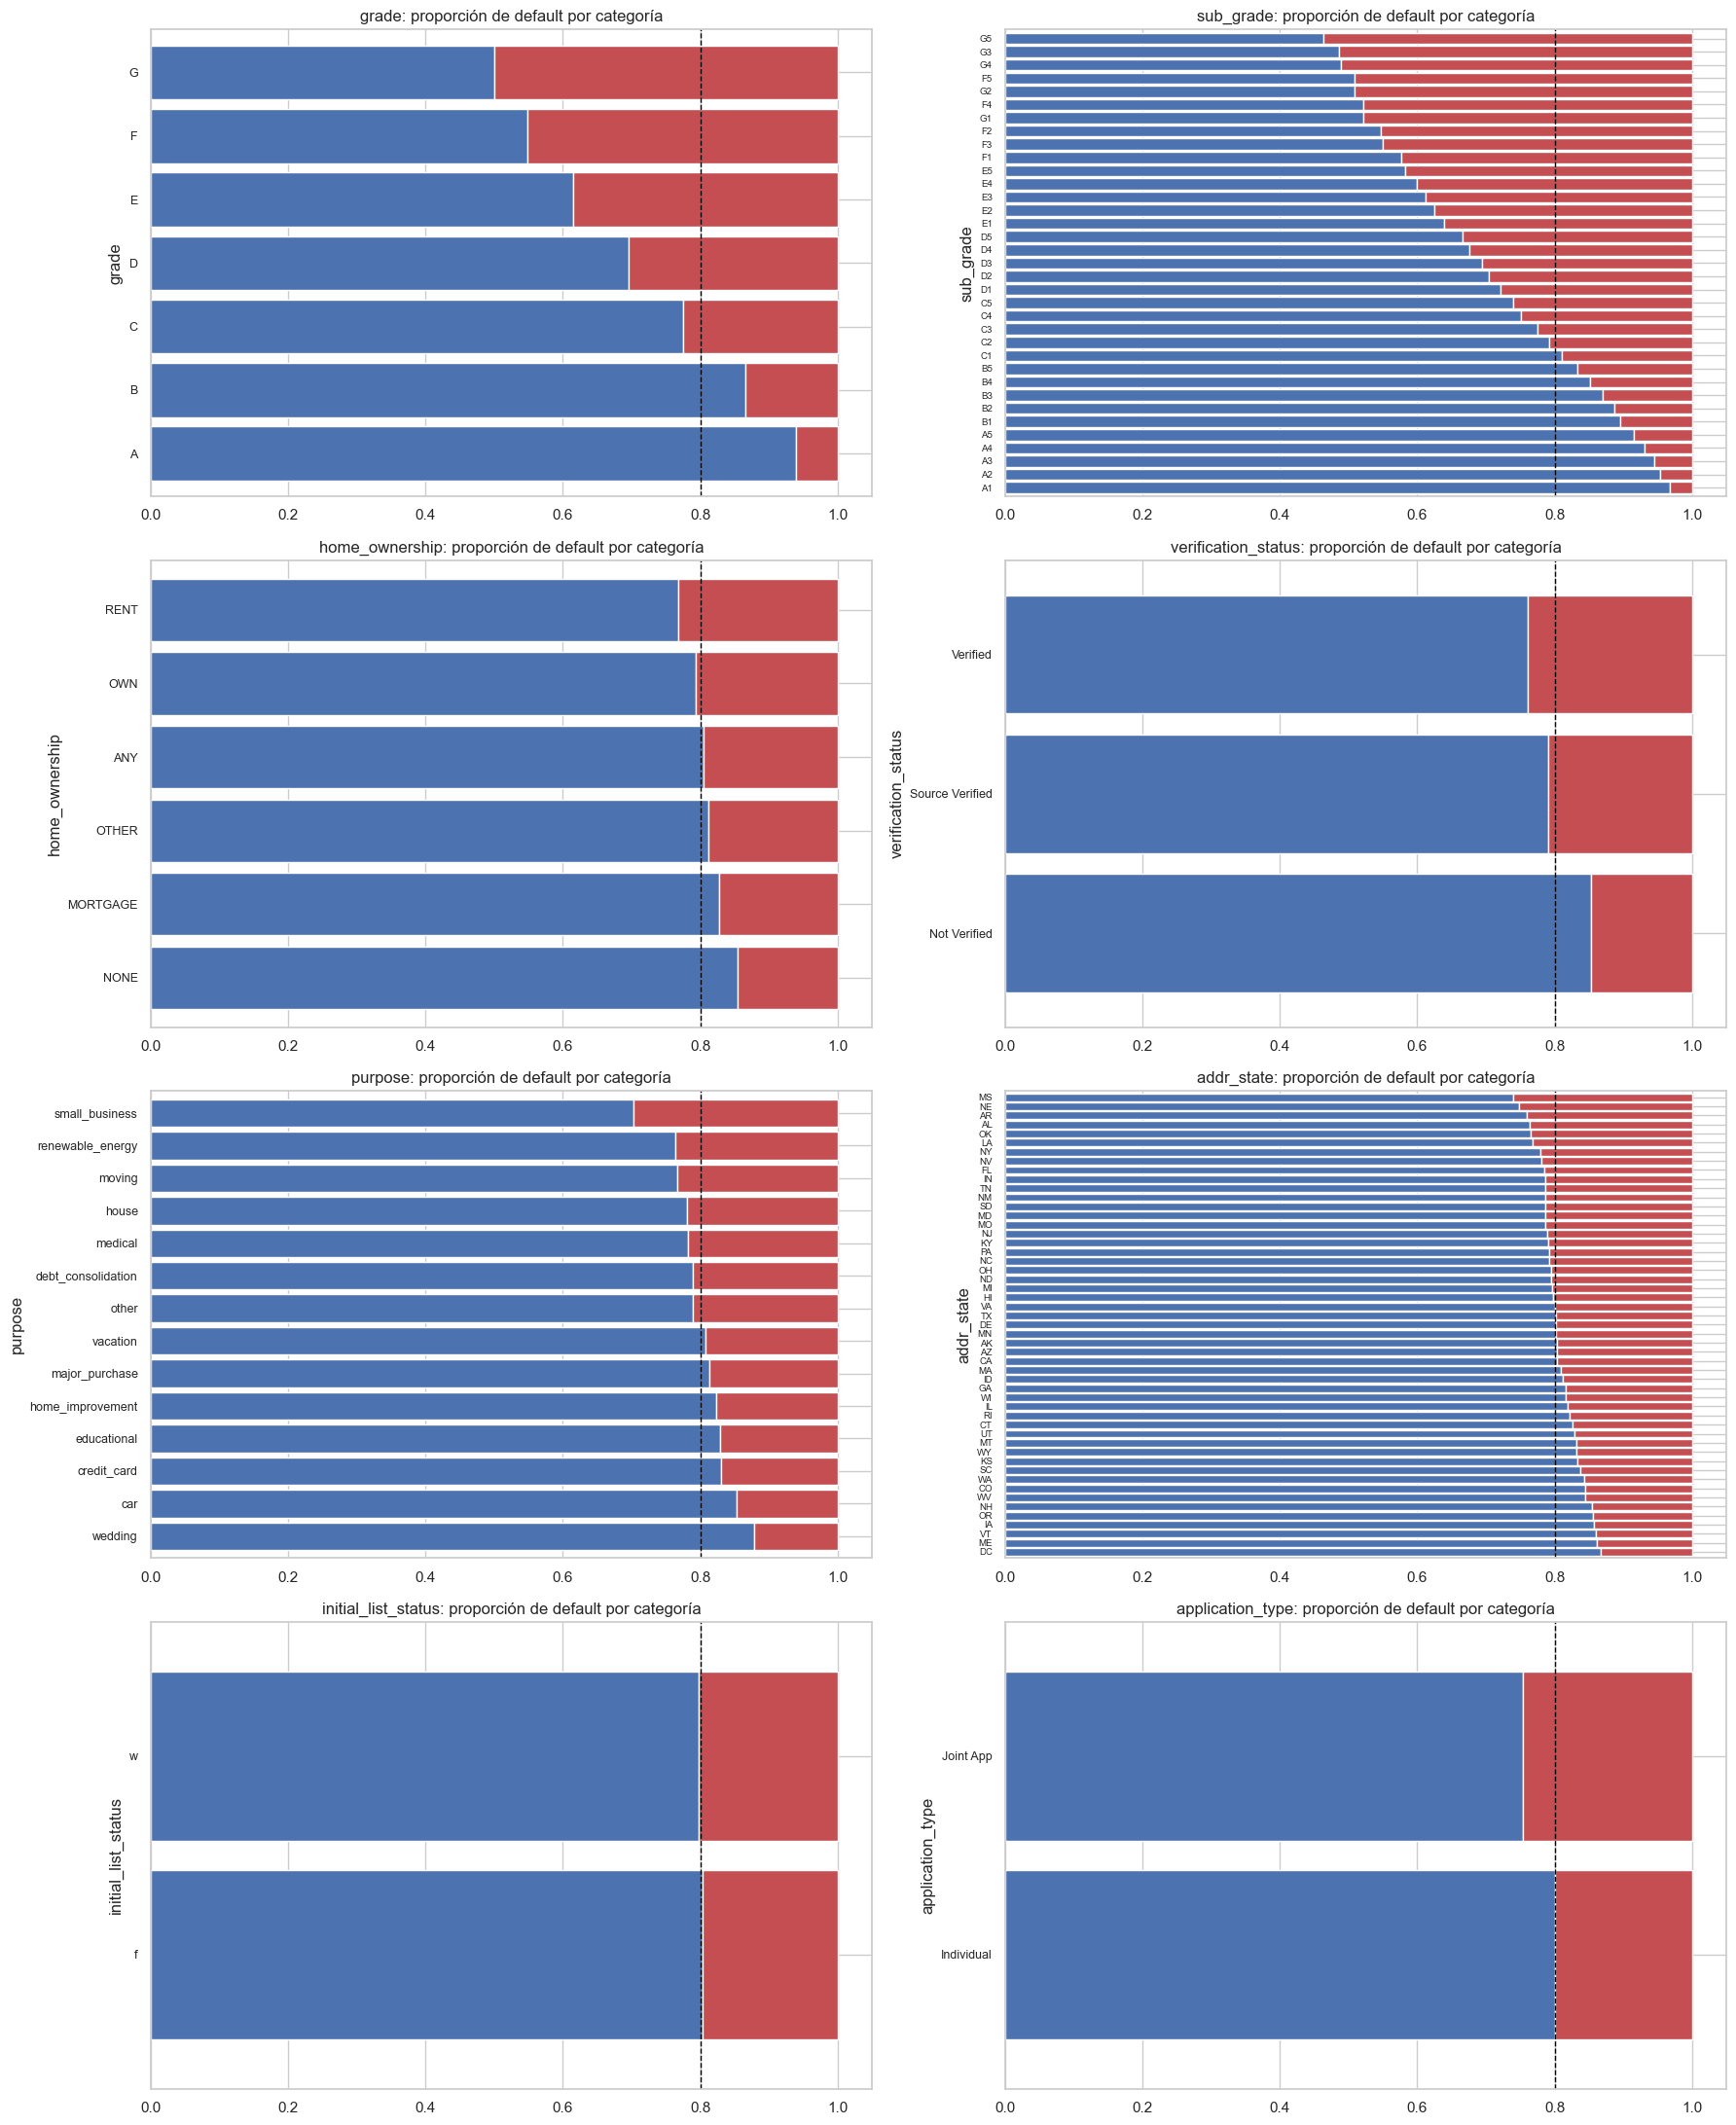

In [23]:
fig, axes = plt.subplots(4, 2, figsize=(18, 22))  # Cuadrícula de 4×2
tasa_global = df[cfg.COL_TARGET].mean()  # Tasa de default global
for ax, col in zip(axes.ravel(), cfg.CATEGORICAS_EDA):  # Un gráfico de barras apiladas por variable
    prop = pd.crosstab(df[col].fillna(cfg.CATEGORIA_FALTANTE), df[cfg.COL_TARGET], normalize="index")  # Proporciones por categoría
    prop = prop.sort_values(1)  # Ordena por tasa de default
    prop.plot.barh(stacked=True, ax=ax, color=["#4C72B0", "#C44E52"], width=0.85, legend=False)  # Barras apiladas 0/1
    ax.axvline(1 - tasa_global, color="black", ls="--", lw=1)  # Línea de la tasa global
    ax.set_title(f"{col}: proporción de default por categoría")  # Título
    ax.tick_params(axis="y", labelsize=7 if len(prop) > 20 else 9)  # Letra más pequeña si hay muchas categorías
fig.tight_layout()  # Ajusta los márgenes
guardar_figura(fig, "01_barras_apiladas")  # Exporta la figura
plt.show()  # Muestra la figura

**Comentario.** La prueba chi-cuadrado rechaza la independencia para todas las categóricas
(p < 0.001), pero la fuerza de asociación (V de Cramér) es muy distinta: `sub_grade`
(0,27) y `grade` (0,26) dominan — la tasa de default crece de forma monótona de 6 % en A a
50 % en G —; siguen `verification_status` (0,09; los ingresos *verificados* tienen más
default, 23,9 %, porque Lending Club verifica sobre todo a los solicitantes más riesgosos),
`home_ownership` (RENT 23,2 %), `purpose` (small_business 29,7 %) y `addr_state` (0,05).
`initial_list_status` y `application_type` son casi independientes del target (V < 0,02).

### Multicolinealidad

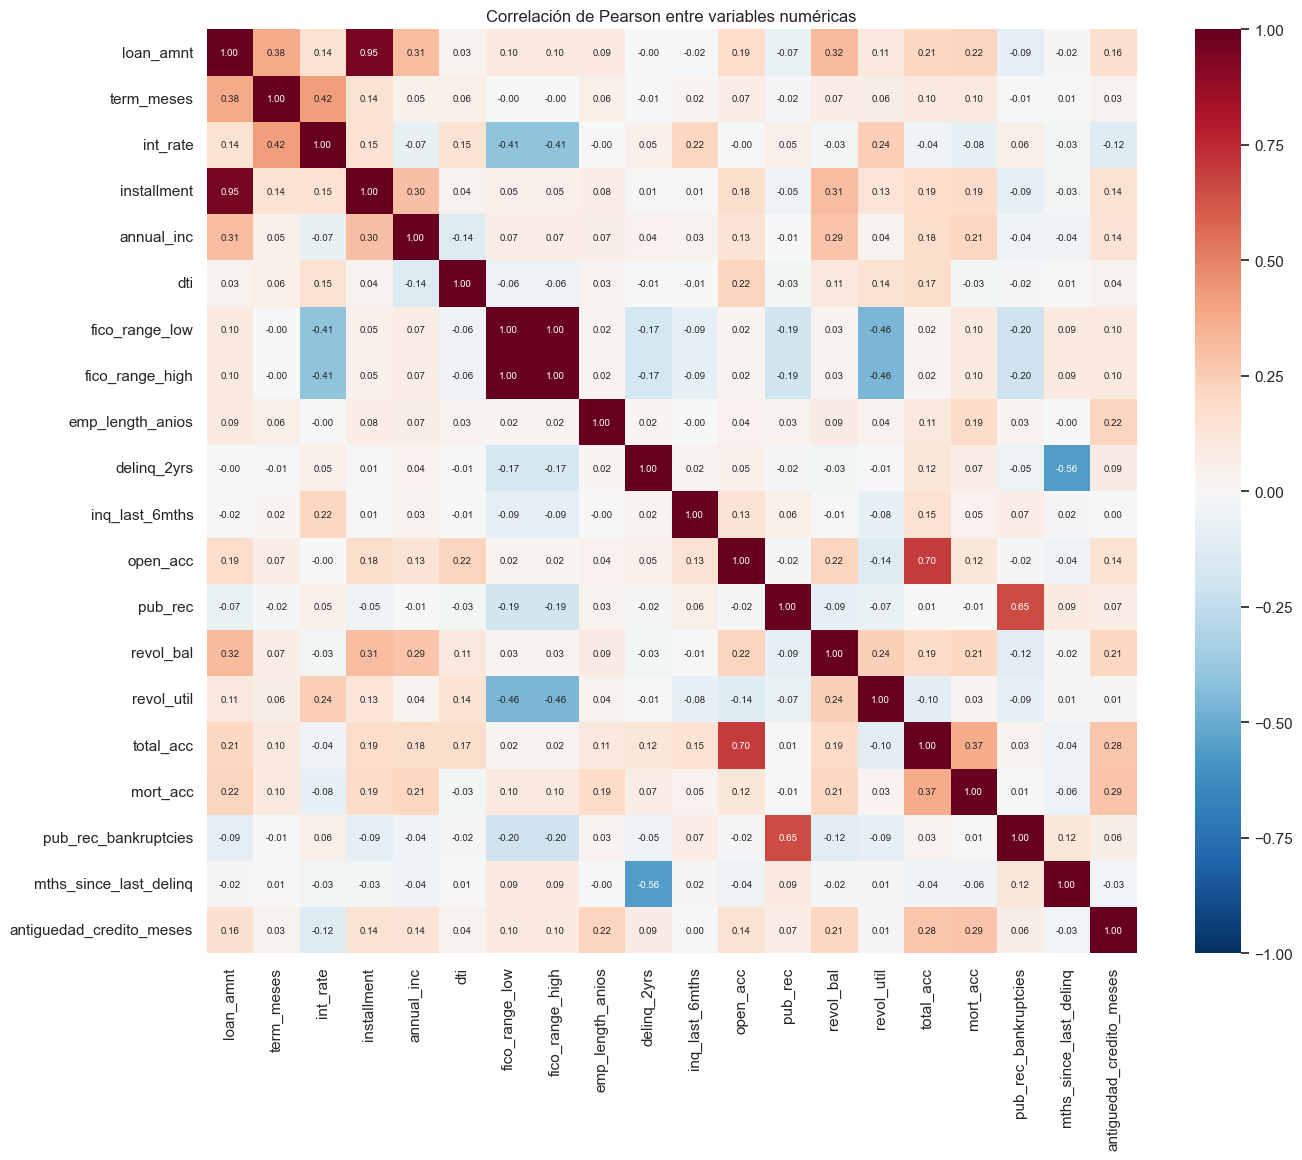

r
fico_range_low  fico_range_high         1.0000
loan_amnt       installment             0.9534
open_acc        total_acc               0.7013
pub_rec         pub_rec_bankruptcies    0.6496
delinq_2yrs     mths_since_last_delinq -0.5560
fico_range_low  revol_util             -0.4600
fico_range_high revol_util             -0.4600
term_meses      int_rate                0.4172
int_rate        fico_range_low         -0.4054
                fico_range_high        -0.4054
loan_amnt       term_meses              0.3809
total_acc       mort_acc                0.3679

In [24]:
corr = df[cfg.NUMERICAS_EDA].corr(method="pearson")  # Matriz de correlación de Pearson
fig, ax = plt.subplots(figsize=(15, 12))  # Figura grande para el mapa de calor
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax, annot_kws={"size": 7})  # Mapa de calor
ax.set_title("Correlación de Pearson entre variables numéricas")  # Título
guardar_figura(fig, "01_correlacion")  # Exporta la figura
plt.show()  # Muestra la figura
pares = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()  # Pares únicos (triángulo superior)
pares.reindex(pares.abs().sort_values(ascending=False).index).head(12).to_frame("r")  # Pares más correlacionados

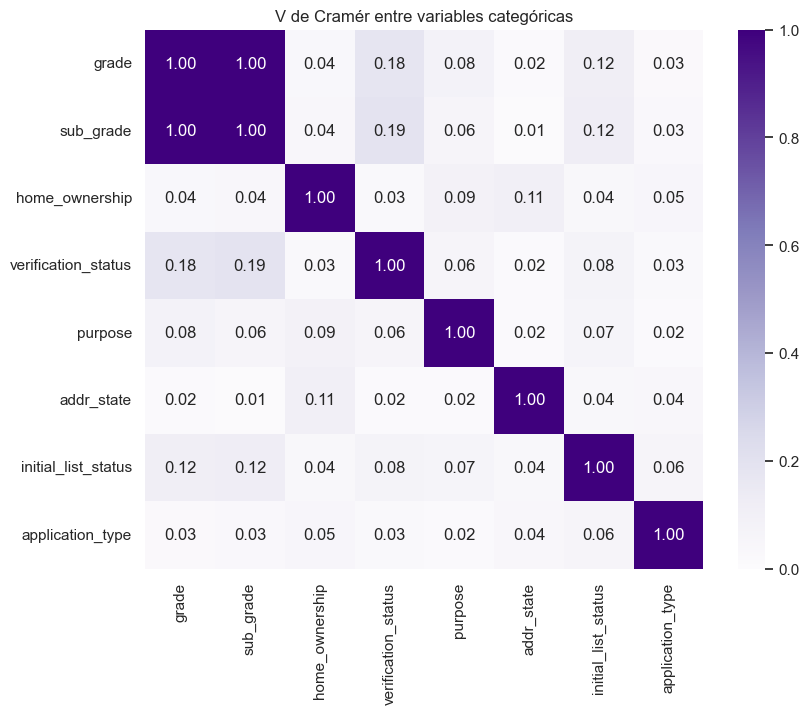

In [25]:
matriz_v = pd.DataFrame(index=cfg.CATEGORICAS_EDA, columns=cfg.CATEGORICAS_EDA, dtype=float)  # Matriz vacía de V de Cramér
for a in cfg.CATEGORICAS_EDA:  # Primera variable del par
    for b in cfg.CATEGORICAS_EDA:  # Segunda variable del par
        matriz_v.loc[a, b] = 1.0 if a == b else v_cramer(df[a].fillna(cfg.CATEGORIA_FALTANTE), df[b].fillna(cfg.CATEGORIA_FALTANTE))  # V de Cramér del par
fig, ax = plt.subplots(figsize=(9, 7))  # Figura para el mapa de calor
sns.heatmap(matriz_v, annot=True, fmt=".2f", cmap="Purples", vmin=0, vmax=1, ax=ax)  # Mapa de calor de V de Cramér
ax.set_title("V de Cramér entre variables categóricas")  # Título
guardar_figura(fig, "01_cramer")  # Exporta la figura
plt.show()  # Muestra la figura

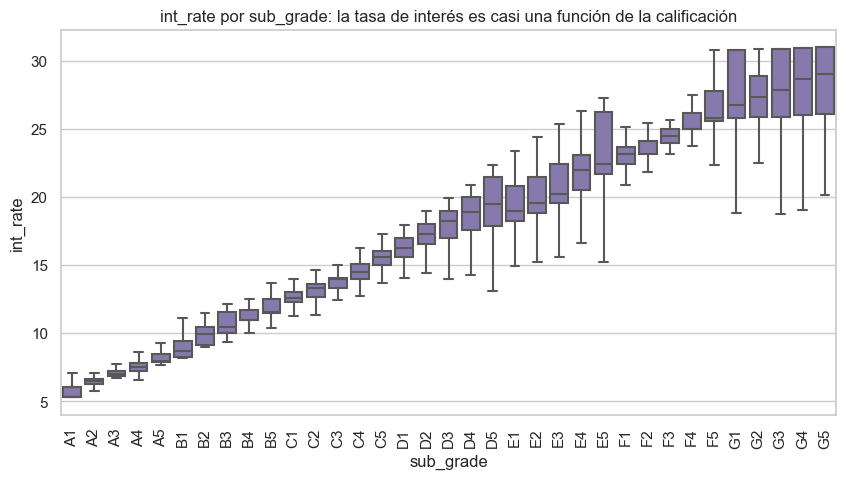

Correlación de Spearman entre fico_range_high e int_rate: -0.416


In [26]:
fig, ax = plt.subplots(figsize=(10, 5))  # Relación entre sub-calificación y tasa de interés
orden = sorted(df["sub_grade"].unique())  # Sub-calificaciones en orden A1…G5
sns.boxplot(data=df, x="sub_grade", y="int_rate", order=orden, showfliers=False, ax=ax, color="#8172B3")  # Tasa de interés por sub-calificación
ax.tick_params(axis="x", rotation=90)  # Rota las etiquetas
ax.set_title("int_rate por sub_grade: la tasa de interés es casi una función de la calificación")  # Título
plt.show()  # Muestra la figura
print("Correlación de Spearman entre fico_range_high e int_rate:", round(stats.spearmanr(df["fico_range_high"], df["int_rate"])[0], 3))  # Redundancia sugerida por el enunciado

**Comentario (multicolinealidad).** Pares con |r| > 0,7: `fico_range_low`–`fico_range_high`
(r = 1,00: el rango siempre mide 4 puntos), `loan_amnt`–`installment` (0,95: la cuota es
función del monto, la tasa y el plazo) y `open_acc`–`total_acc` (0,70, justo en el límite).
Entre categóricas, `grade`–`sub_grade` tiene V ≈ 1 (una determina a la otra) y la tasa de
interés es prácticamente una función de la sub-calificación. La redundancia sugerida por el
enunciado `fico_range_high`–`int_rate` es moderada (ρ = −0,42), no suficiente para excluir.

**Decisión:** se excluyen `fico_range_low`, `installment` y `sub_grade`; se conservan
`open_acc` y `total_acc` (r en el límite y significado distinto) e `int_rate` junto a
`grade` (la tasa aporta variación dentro de cada grado).

### Visualizaciones avanzadas

El *pairplot* y la matriz de dispersión dibujan cada punto, por lo que (como permite el
enunciado) se usa una **muestra aleatoria de 5.000 filas solo para estos dos gráficos**.
Ningún cálculo ni modelo usa la muestra.

C:\Users\user-pc\.conda\envs\ml_venv\lib\site-packages\seaborn\axisgrid.py:118: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)


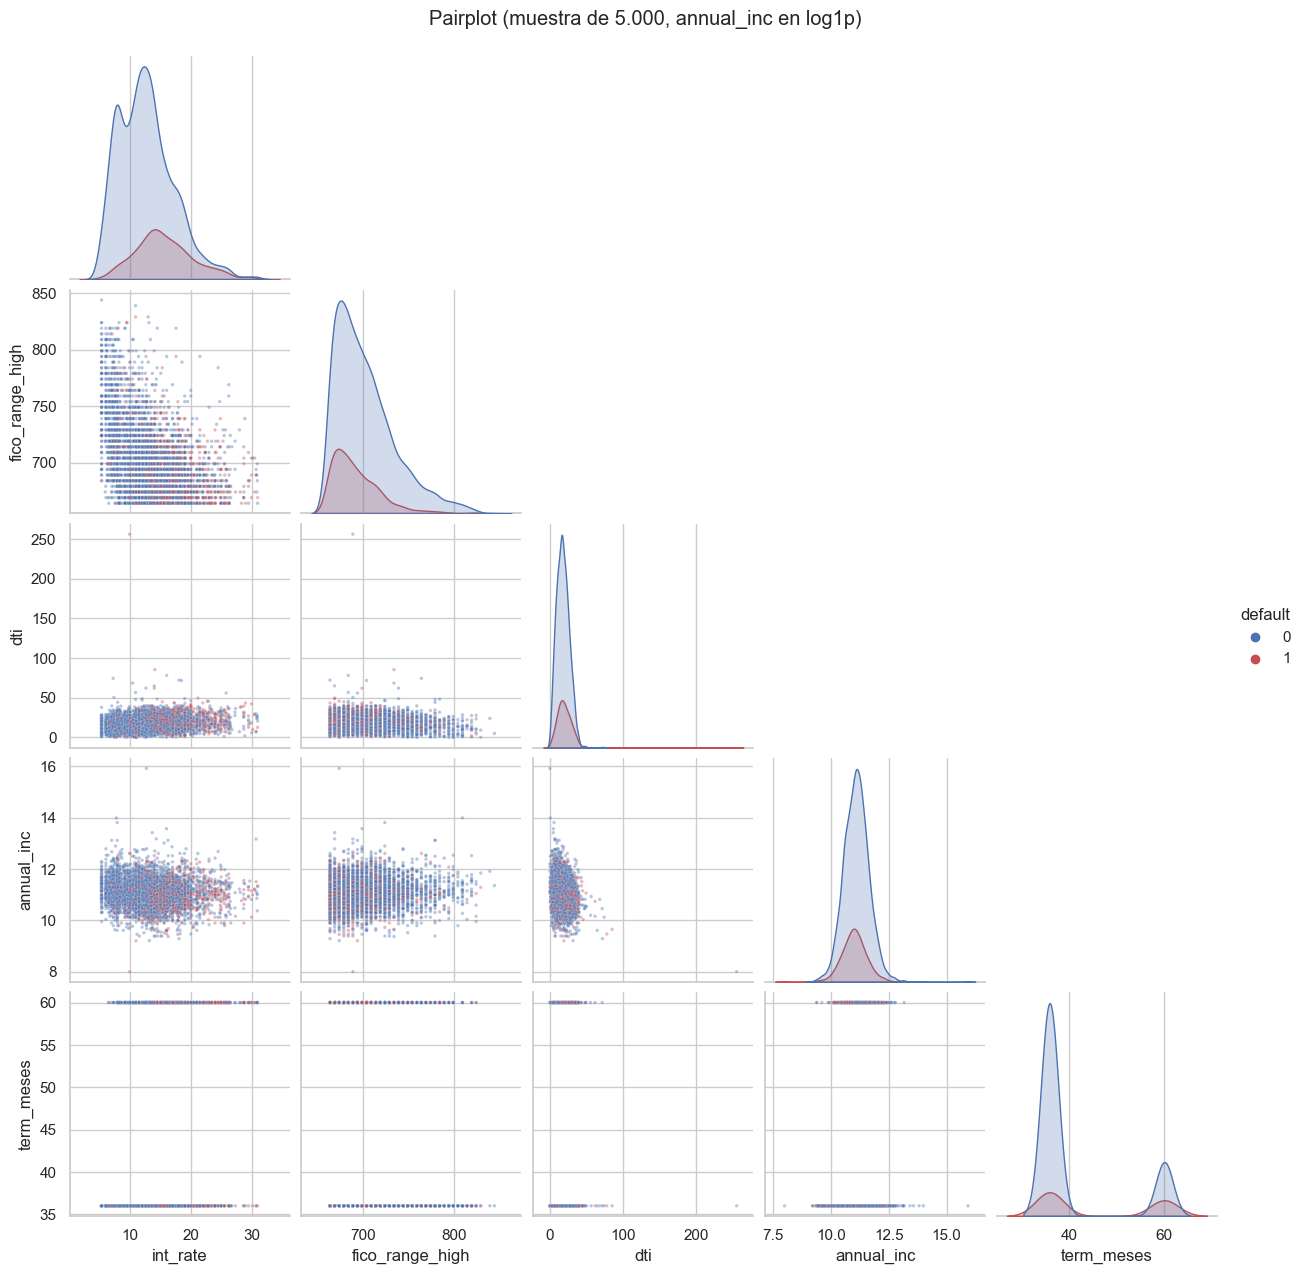

In [27]:
top_vars = ["int_rate", "fico_range_high", "dti", "annual_inc", "term_meses"]  # Variables más relevantes
muestra_viz = df[top_vars + [cfg.COL_TARGET]].dropna().sample(5000, random_state=cfg.SEMILLA)  # Muestra solo para visualización
muestra_viz["annual_inc"] = np.log1p(muestra_viz["annual_inc"])  # Escala logarítmica para el ingreso
g = sns.pairplot(muestra_viz, hue=cfg.COL_TARGET, palette=["#4C72B0", "#C44E52"], plot_kws={"s": 6, "alpha": 0.4}, corner=True)  # Pairplot por clase
g.fig.suptitle("Pairplot (muestra de 5.000, annual_inc en log1p)", y=1.02)  # Título
plt.show()  # Muestra la figura

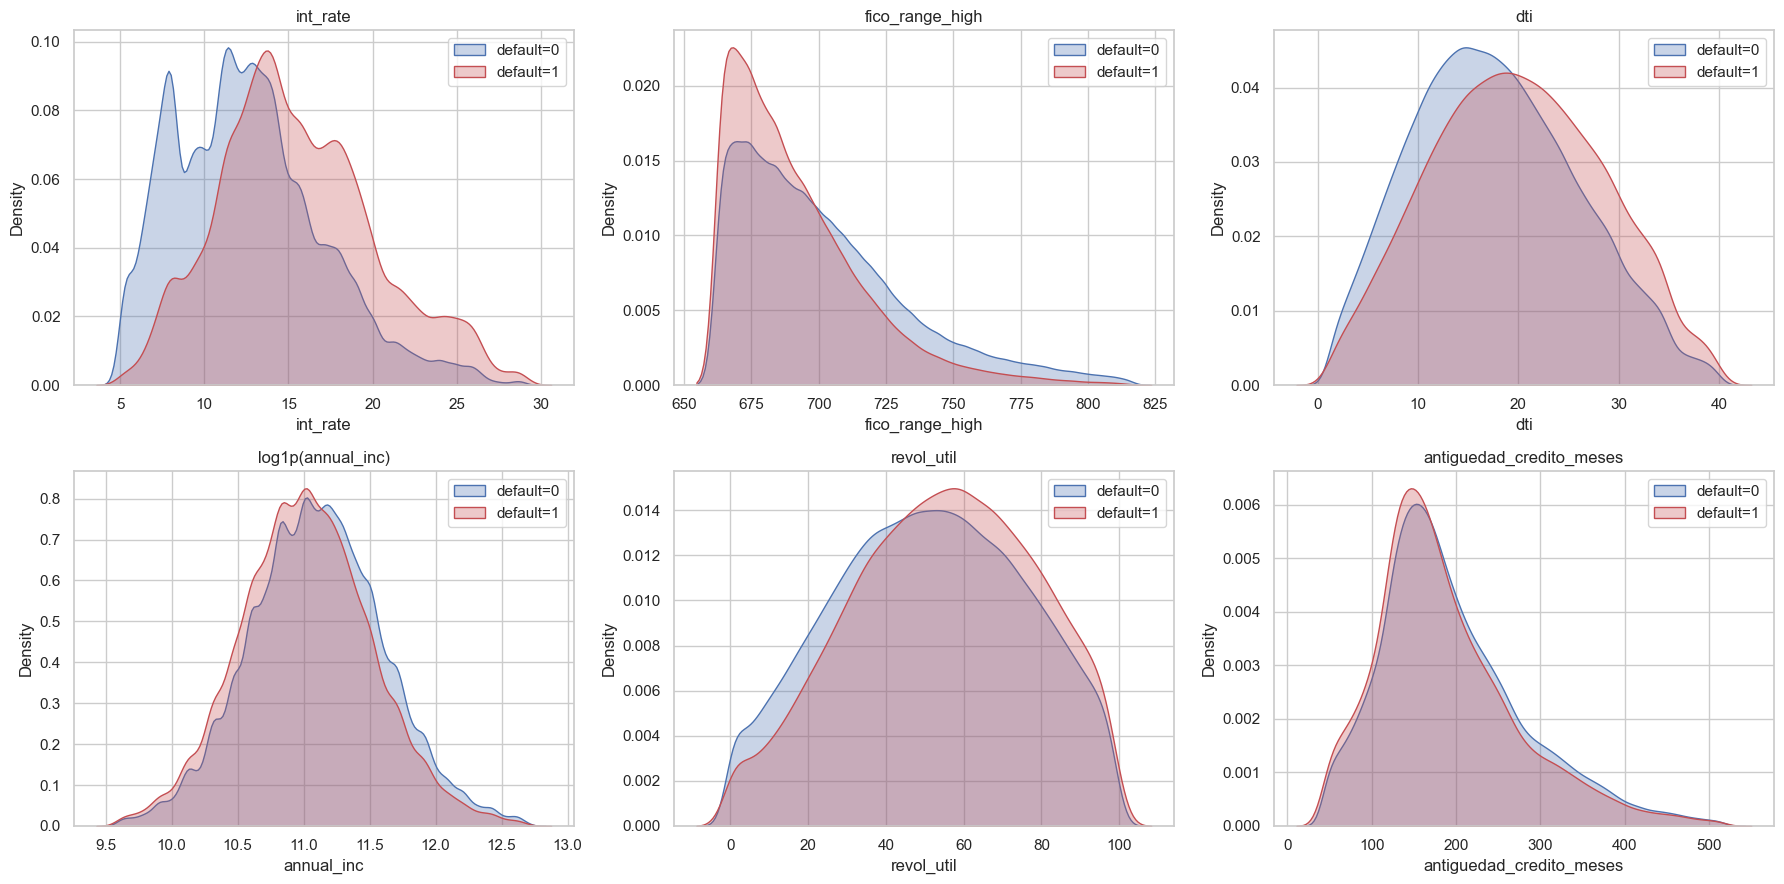

In [28]:
fig, axes = plt.subplots(2, 3, figsize=(18, 9))  # KDE comparativos por clase (datos completos)
for ax, col in zip(axes.ravel(), ["int_rate", "fico_range_high", "dti", "annual_inc", "revol_util", "antiguedad_credito_meses"]):  # Variables relevantes
    d = df[[col, cfg.COL_TARGET]].dropna()  # Datos sin nulos
    if col == "annual_inc":  # El ingreso se grafica en escala log
        d[col] = np.log1p(d[col])  # Transformación log1p
    d = d[d[col].between(d[col].quantile(0.005), d[col].quantile(0.995))]  # Recorta colas extremas solo para visualizar
    for clase, color in [(0, "#4C72B0"), (1, "#C44E52")]:  # Una curva por clase
        sns.kdeplot(d.loc[d[cfg.COL_TARGET] == clase, col], ax=ax, color=color, fill=True, alpha=0.3, label=f"default={clase}", bw_adjust=1.5)  # Densidad
    ax.set_title(col if col != "annual_inc" else "log1p(annual_inc)")  # Título
    ax.legend()  # Leyenda
fig.tight_layout()  # Ajusta los márgenes
guardar_figura(fig, "01_kde")  # Exporta la figura
plt.show()  # Muestra la figura

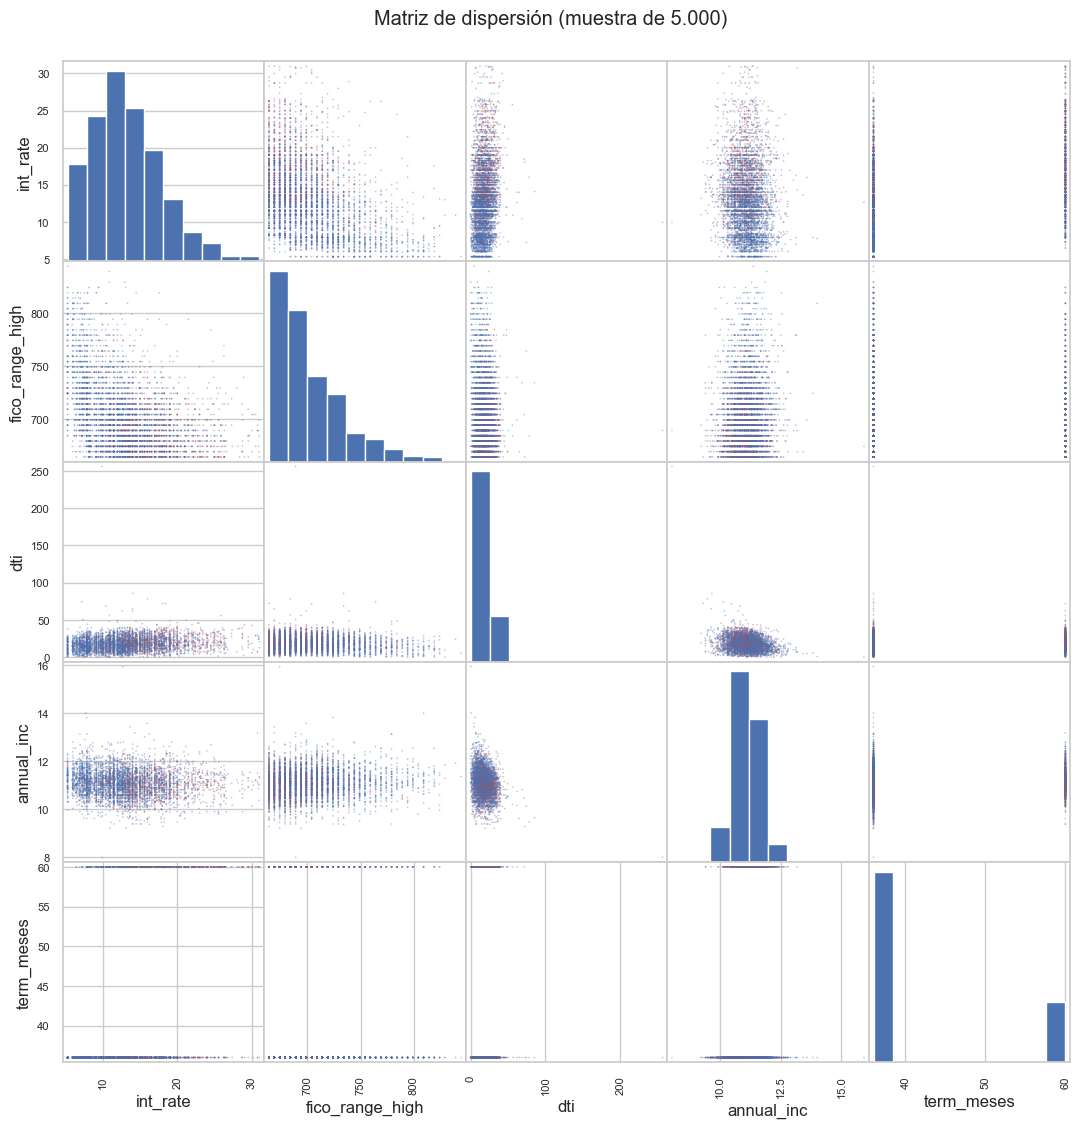

In [29]:
colores = muestra_viz[cfg.COL_TARGET].map({0: "#4C72B0", 1: "#C44E52"})  # Color de cada punto según la clase
pd.plotting.scatter_matrix(muestra_viz[top_vars], c=colores, figsize=(13, 13), s=6, alpha=0.4, diagonal="hist")  # Matriz de dispersión de 5 variables
plt.suptitle("Matriz de dispersión (muestra de 5.000)", y=0.92)  # Título
plt.show()  # Muestra la figura

**Comentario.** Las densidades muestran solapamiento amplio entre clases: ninguna variable
separa por sí sola. Las diferencias más visibles son el desplazamiento de `int_rate` hacia
la derecha y de `fico_range_high` hacia la izquierda en los defaults. En el *pairplot* y la
matriz de dispersión no aparecen fronteras no lineales claras; sí se aprecia la estructura
discreta de `term_meses` y de FICO, y la relación decreciente entre FICO y tasa de interés.

## Valores faltantes (análisis detallado)

In [30]:
print(f"Columnas sin nulos: {(nulos_todas['pct_nulos'] == 0).sum()} | con nulos: {(nulos_todas['pct_nulos'] > 0).sum()} | "
      f"> 30 %: {(nulos_todas['pct_nulos'] > 30).sum()} | > 70 %: {(nulos_todas['pct_nulos'] > 70).sum()}")  # Resumen de las 151 columnas
nulos_todas.head(40)  # Las 40 columnas con más nulos

Columnas sin nulos: 46 | con nulos: 105 | > 30 %: 58 | > 70 %: 42


,n_nulos,pct_nulos
next_pymnt_d,1345310,100.0000
member_id,1345310,100.0000
orig_projected_additional_accrued_interest,1341551,99.7206
hardship_start_date,1339556,99.5723
hardship_length,1339556,99.5723
hardship_type,1339556,99.5723
hardship_reason,1339556,99.5723
hardship_status,1339556,99.5723
deferral_term,1339556,99.5723
hardship_amount,1339556,99.5723


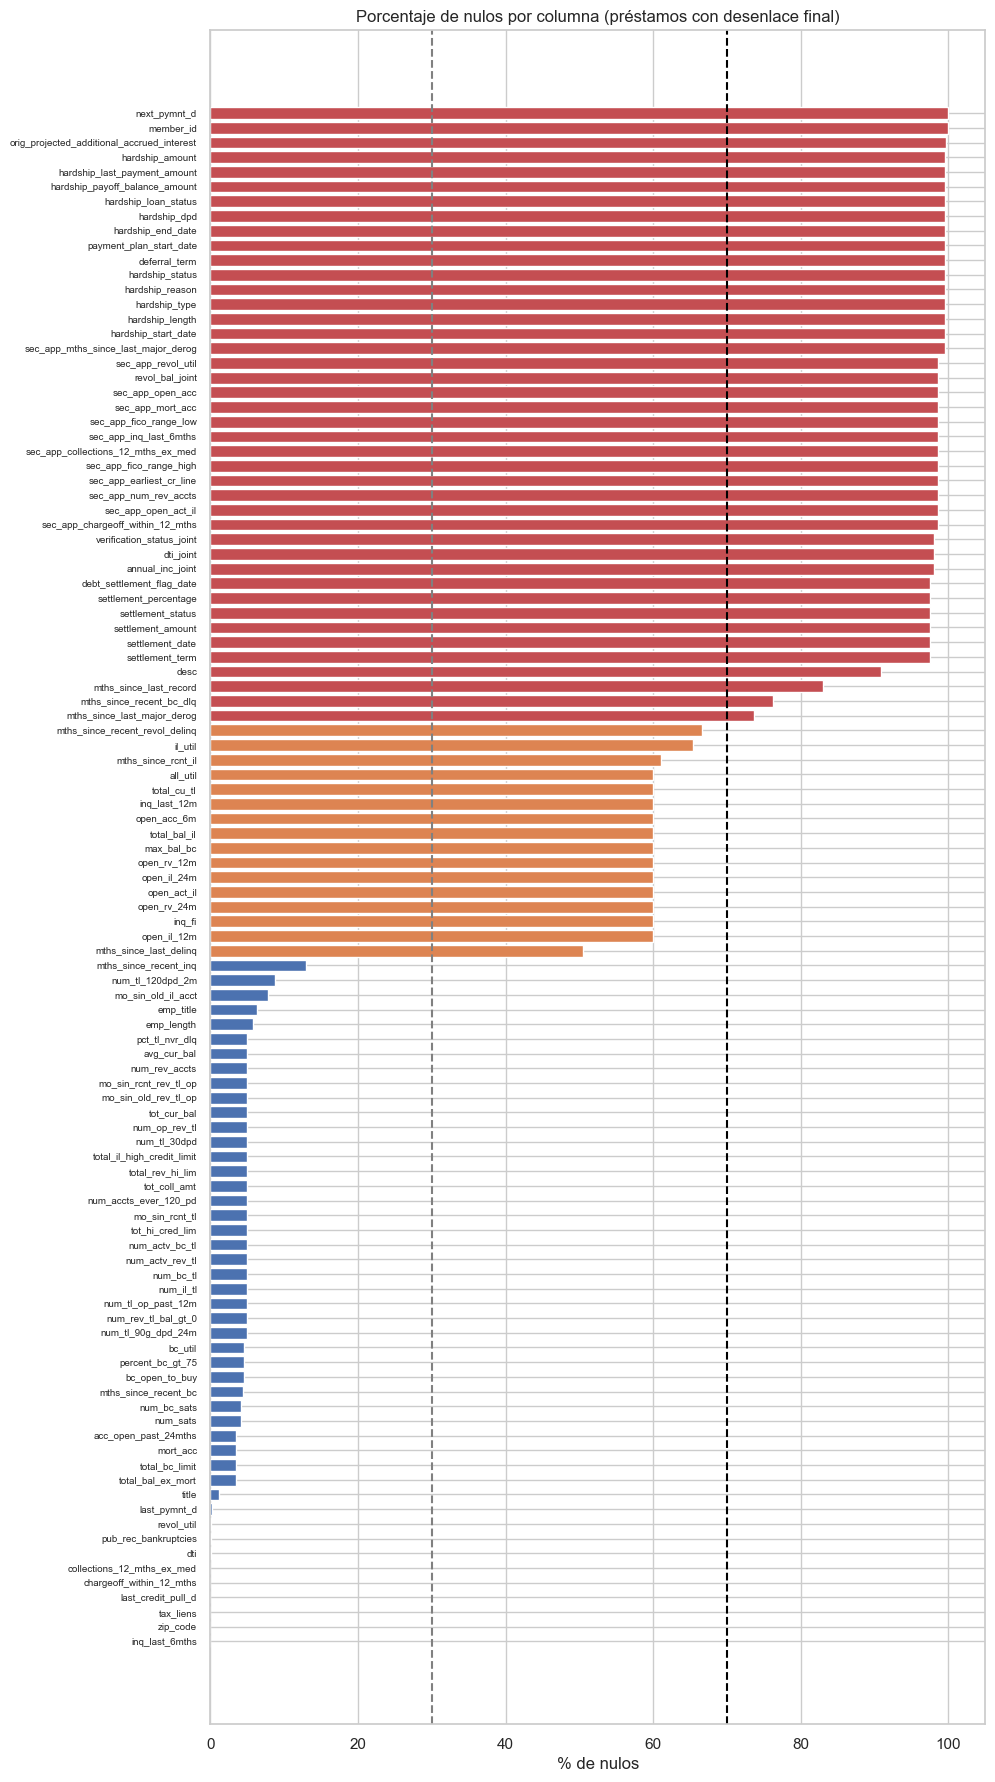

In [31]:
fig, ax = plt.subplots(figsize=(10, 22))  # Figura alta para las columnas con nulos
d = nulos_todas.loc[nulos_todas["pct_nulos"] > 0, "pct_nulos"].sort_values()  # Columnas con nulos
ax.barh(d.index, d.values, color=["#C44E52" if v > 70 else "#DD8452" if v > 30 else "#4C72B0" for v in d.values])  # Barras por severidad
ax.axvline(30, color="gray", ls="--"); ax.axvline(70, color="black", ls="--")  # Umbrales 30 % y 70 %
ax.set_xlabel("% de nulos"); ax.tick_params(axis="y", labelsize=7)  # Etiquetas
ax.set_title("Porcentaje de nulos por columna (préstamos con desenlace final)")  # Título
guardar_figura(fig, "01_nulos_columnas")  # Exporta la figura
plt.show()  # Muestra la figura

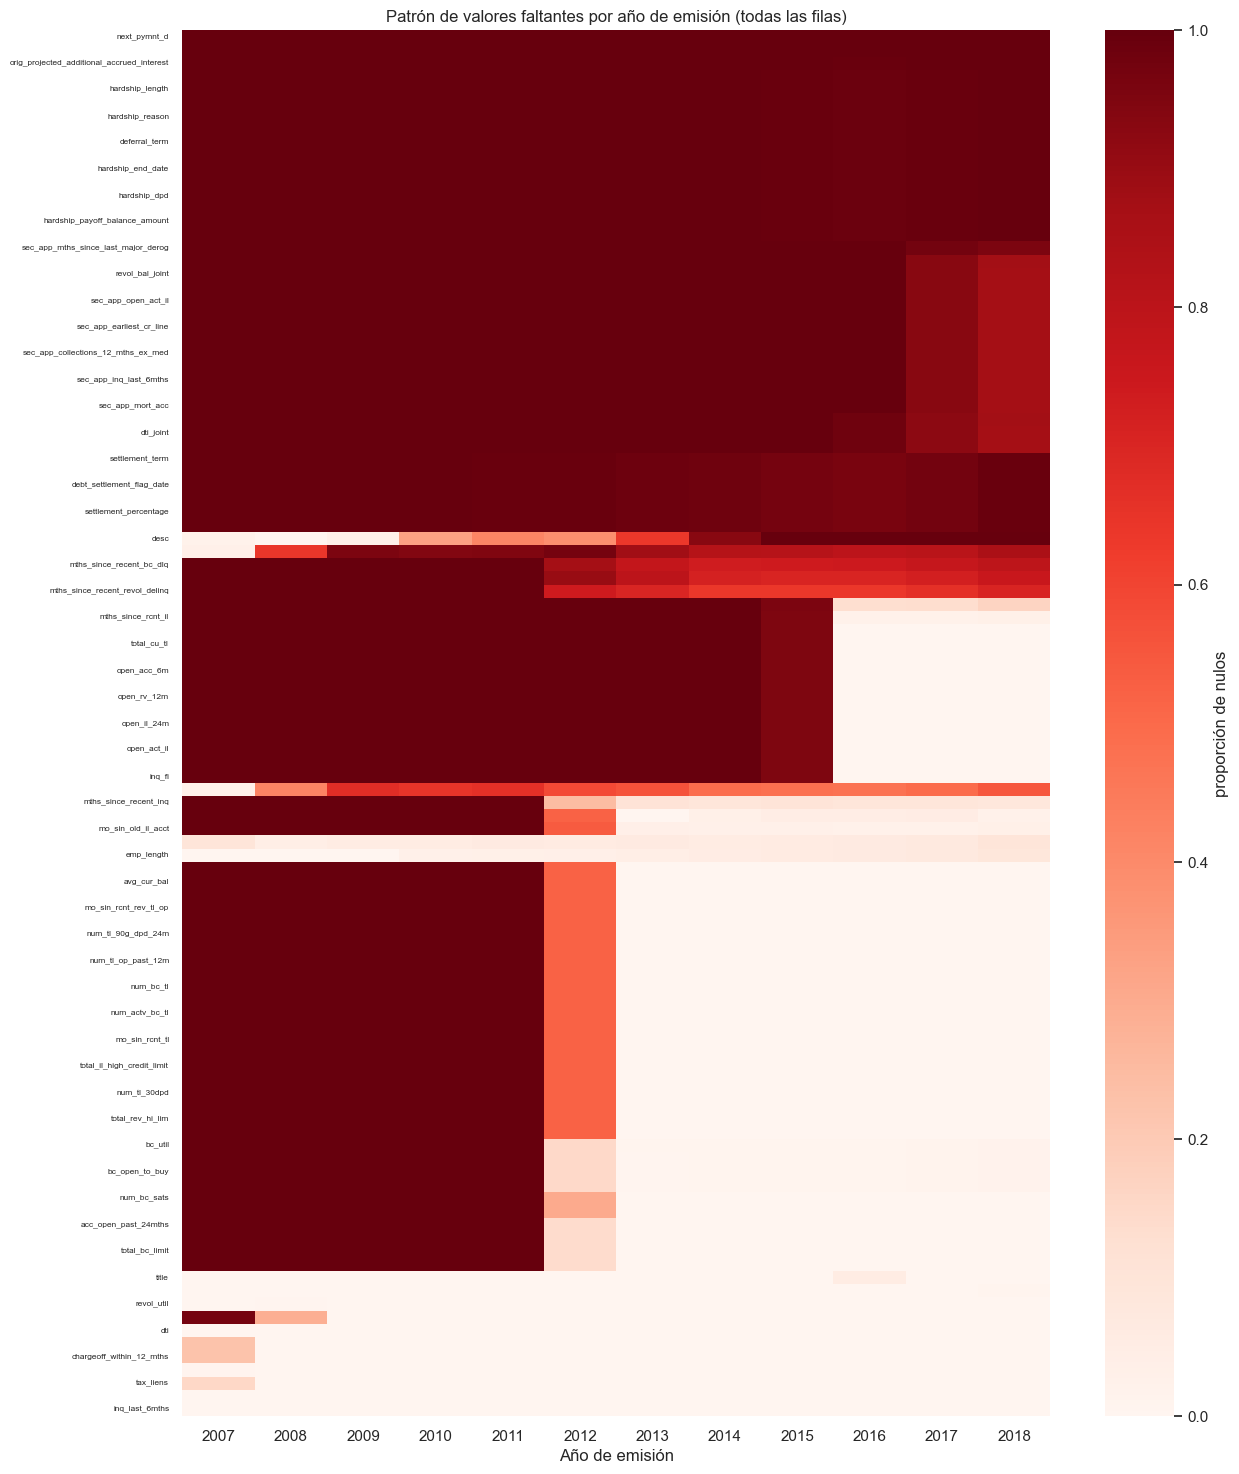

In [32]:
fig, ax = plt.subplots(figsize=(14, 18))  # Mapa de calor del patrón de nulos a lo largo del tiempo
sns.heatmap(nulos_por_anio.T, cmap="Reds", vmin=0, vmax=1, ax=ax, cbar_kws={"label": "proporción de nulos"})  # Filas = columnas, columnas = año
ax.set_xlabel("Año de emisión"); ax.tick_params(axis="y", labelsize=6)  # Etiquetas
ax.set_title("Patrón de valores faltantes por año de emisión (todas las filas)")  # Título
guardar_figura(fig, "01_nulos_por_anio")  # Exporta la figura
plt.show()  # Muestra la figura

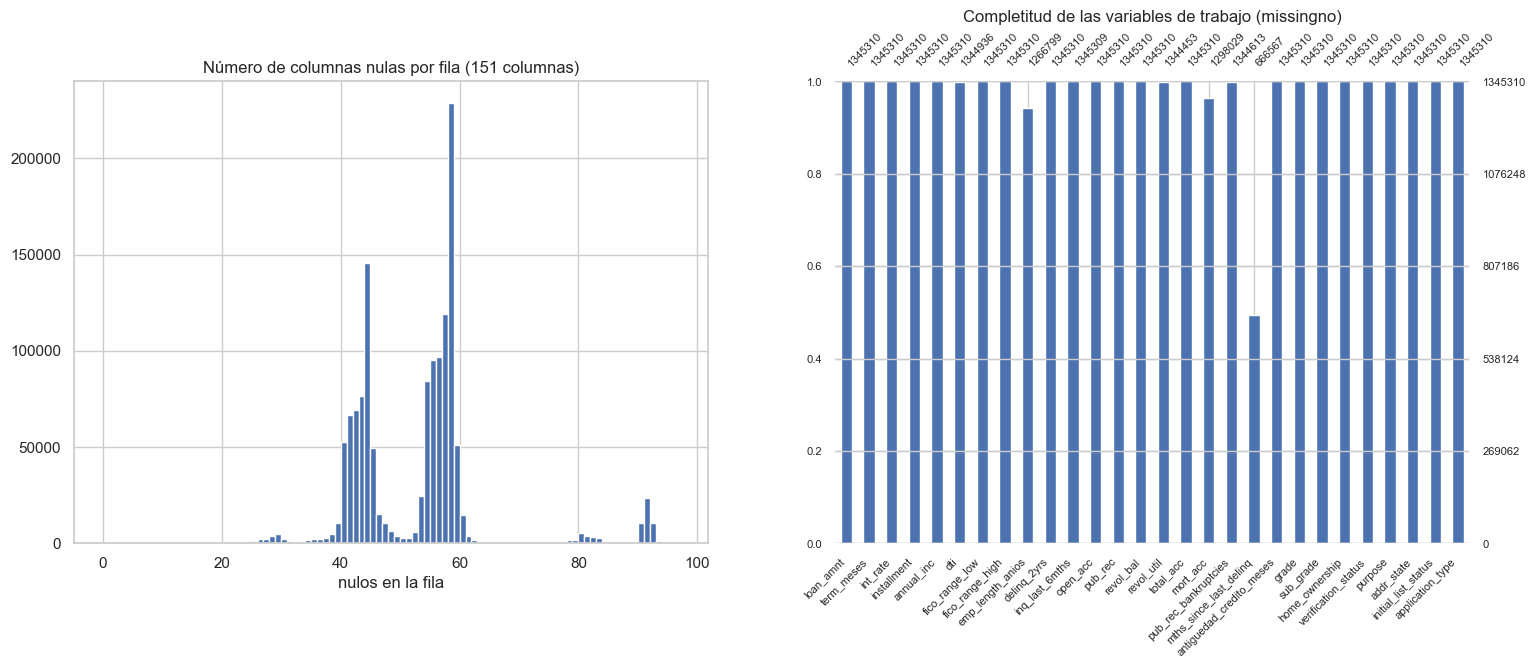

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))  # Concentración de nulos por fila + missingno
axes[0].hist(nulos_por_fila, bins=range(0, int(nulos_por_fila.max()) + 2), color="#4C72B0")  # Número de nulos por fila
axes[0].set_title("Número de columnas nulas por fila (151 columnas)"); axes[0].set_xlabel("nulos en la fila")  # Títulos
msno.bar(df[cfg.NUMERICAS_EDA + cfg.CATEGORICAS_EDA], ax=axes[1], fontsize=8, color="#4C72B0")  # Completitud de las variables de trabajo
axes[1].set_title("Completitud de las variables de trabajo (missingno)")  # Título
plt.show()  # Muestra la figura

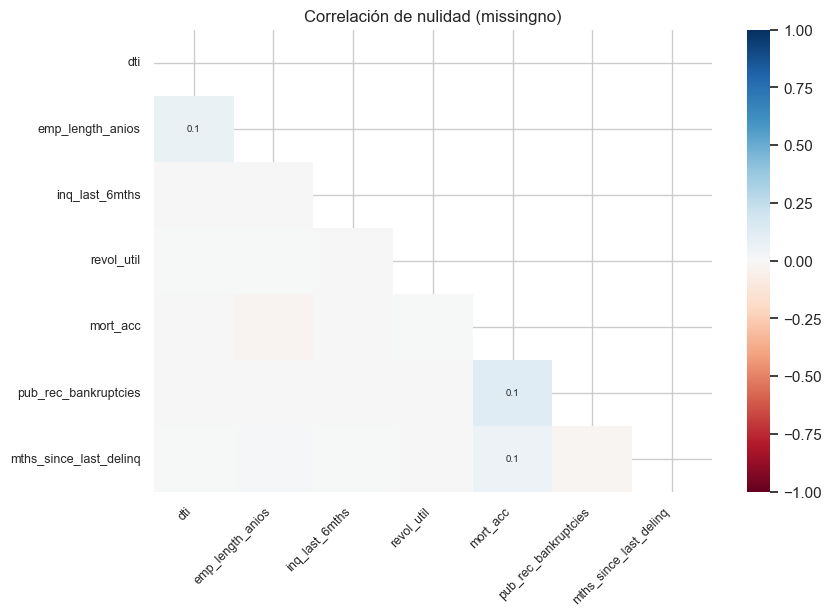

In [34]:
con_nulos = [c for c in cfg.NUMERICAS_EDA + cfg.CATEGORICAS_EDA if df[c].isna().any()]  # Variables de trabajo con algún nulo
msno.heatmap(df[con_nulos], figsize=(9, 6), fontsize=9)  # Correlación de nulidad entre variables (datos completos)
plt.title("Correlación de nulidad (missingno)")  # Título
plt.show()  # Muestra la figura

In [35]:
mcar_todas["relacion_con_default"] = np.where(mcar_todas["p_valor"] < cfg.ALFA, "NO MCAR (p < 0.05)", "compatible con MCAR")  # Interpretación
mcar_trabajo = mcar_todas.reindex([c for c in ["emp_length", "mths_since_last_delinq", "mort_acc", "revol_util", "dti", "pub_rec_bankruptcies", "earliest_cr_line", "inq_last_6mths"] if c in mcar_todas.index])  # Columnas de trabajo con nulos
display(mcar_trabajo)  # Prueba sobre las variables de trabajo
print("Resumen sobre las", len(mcar_todas), "columnas con nulos parciales:")  # Resumen general
mcar_todas["relacion_con_default"].value_counts()  # Cuántas columnas muestran nulos relacionados con el target

,pct_nulos,tasa_default_si_nulo,tasa_default_si_presente,chi2,p_valor,relacion_con_default
columna,,,,,,
emp_length,5.8359,0.2691,0.1953,"2,520.7329",0.0000,NO MCAR (p < 0.05)
mths_since_last_delinq,50.4525,0.1926,0.2068,420.3151,0.0000,NO MCAR (p < 0.05)
mort_acc,3.5145,0.1456,0.2016,893.5316,0.0000,NO MCAR (p < 0.05)
revol_util,0.0637,0.2100,0.1996,0.5181,0.4716,compatible con MCAR
dti,0.0278,0.1898,0.1996,0.1672,0.6826,compatible con MCAR
pub_rec_bankruptcies,0.0518,0.1693,0.1996,3.8272,0.0504,compatible con MCAR
inq_last_6mths,0.0001,0.0000,0.1996,0.0000,1.0000,compatible con MCAR


Resumen sobre las 103 columnas con nulos parciales:


relacion_con_default
NO MCAR (p < 0.05)     95
compatible con MCAR     8
Name: count, dtype: int64

La prueba anterior contrasta, para cada columna, si **estar nulo** es independiente del
target (chi-cuadrado sobre la tabla 2×2 nulo × default). Un valor p < 0.05 indica que
los nulos **no son completamente al azar (no MCAR)**: su presencia aporta información sobre
el riesgo. Con 1,3 millones de filas casi cualquier diferencia resulta significativa, por lo
que también se reporta la magnitud (tasa de default con y sin dato).

In [36]:
plan = pd.DataFrame({  # Plan de tratamiento de nulos para las variables de trabajo
    "pct_nulos": [100 * df[c].isna().mean() for c in cfg.NUMERICAS_EDA + cfg.CATEGORICAS_EDA],  # % de nulos
}, index=cfg.NUMERICAS_EDA + cfg.CATEGORICAS_EDA)  # Índice = variables
plan = plan[plan["pct_nulos"] > 0].sort_values("pct_nulos", ascending=False)  # Solo las que tienen nulos
plan["tratamiento"] = [  # Regla de tratamiento por variable
    "Indicador de nulo + imputación con mediana de train (nulo = sin morosidad registrada)" if c == "mths_since_last_delinq"  # Caso no MCAR con 30–70 % de nulos
    else "Indicador de nulo + imputación con mediana de train (nulos no MCAR)" if c in cfg.VARIABLES_CON_INDICADOR  # Pocos nulos pero informativos
    else "Imputación con mediana de train" if c in cfg.NUMERICAS_EDA  # Numéricas con pocos nulos
    else "Categoría 'DESCONOCIDO'"  # Categóricas
    for c in plan.index]  # Recorre cada variable
plan  # Muestra el plan

,pct_nulos,tratamiento
mths_since_last_delinq,50.4525,Indicador de nulo + imputación con mediana de ...
emp_length_anios,5.8359,Indicador de nulo + imputación con mediana de ...
mort_acc,3.5145,Indicador de nulo + imputación con mediana de ...
revol_util,0.0637,Imputación con mediana de train
pub_rec_bankruptcies,0.0518,Imputación con mediana de train
dti,0.0278,Imputación con mediana de train
inq_last_6mths,0.0001,Imputación con mediana de train


Para las 151 columnas originales el criterio es: **> 70 % de nulos → eliminar**; 30–70 % →
imputación avanzada o indicador; < 30 % → mediana/moda o categoría "DESCONOCIDO". Además,
se excluyen **por fuga de información** todas las variables registradas después de la
originación (pagos, recuperaciones, `last_*`, `hardship_*`, `settlement_*`, `out_prncp`, etc.),
porque solo se conocen cuando el préstamo ya está en curso o terminado.

**Comentario (faltantes).** De las 151 columnas, 46 no tienen nulos, 58 superan el 30 % y
42 el 70 % (datos de co-solicitante, *hardship*, *settlement*, `desc`, `member_id` al 100 %).
El mapa por año muestra que los nulos son **sistemáticos por época**: muchas variables de
buró (`open_acc_6m`, `il_util`, `mths_since_rcnt_il`…) solo existen desde finales de 2015
(95 % nulos en 2015, ≈ 0 % desde 2016), las de co-solicitante aparecen desde 2016 (solicitudes
conjuntas) y `mort_acc` falta en todos los préstamos anteriores a 2012. Es decir,
los nulos se concentran en columnas y periodos, no en filas aisladas. En 95 de las 103
columnas con nulos parciales la probabilidad de faltar está relacionada con el default
(**no MCAR**). Entre las variables de trabajo: sin `emp_length` el default sube a 26,9 %
(vs 19,5 %), sin `mort_acc` baja a 14,6 % (préstamos antiguos) y sin
`mths_since_last_delinq` es 19,3 % (vs 20,7 %). Por eso esas tres reciben un **indicador de
nulo** además de la imputación con la mediana de train.

## 2.5 Resumen ejecutivo del EDA

| Aspecto | Hallazgo | Decisión para el preprocesamiento |
|---|---|---|
| Tamaño y target | 2.260.701 filas; 1.345.310 con desenlace final; 20,0 % default (4:1) | Filtrar a `Fully Paid`/`Charged Off`; partición 80/20 estratificada; AUC como criterio; umbral optimizado en train |
| Calidad | `id` sin duplicados; 2 filas de totales al final; valores implausibles (`dti` = 999, `revol_util` = 892) | Se conservan todas las filas (sin muestreo ni eliminación); escalado estándar |
| Asimetría | Ninguna variable normal; `annual_inc` y `revol_bal` extremadamente asimétricas | `log1p` en ambas |
| Predictores más prometedores | `grade`/`int_rate`, `term`, FICO, `dti`, `verification_status`, `home_ownership`, `purpose`, `revol_util`, `inq_last_6mths`, `mort_acc` | Se incluyen todas las variables conocidas al originar el préstamo (17 numéricas + 7 categóricas) |
| Multicolinealidad | FICO bajo/alto (r = 1), monto/cuota (0,95), `grade`/`sub_grade` (V ≈ 1) | Excluir `fico_range_low`, `installment`, `sub_grade` |
| Categorías raras | < 1 % en `grade`, `home_ownership`, `purpose`, `addr_state` | Agrupar en `OTROS` (aprendido en train) |
| Faltantes | 42 columnas > 70 %; nulos por época; `mths_since_last_delinq` 50 %; nulos no MCAR | Eliminar columnas > 70 % y de fuga; indicador + mediana en 3 variables |
| Fuga de información | Pagos, recuperaciones, `last_*`, *hardship*, *settlement* | Excluidas |
| Balanceo | Desbalance moderado | Sin remuestreo; métricas y umbral adecuados |